# 9장. 회귀 분석으로 숫자 예측하기

이 Notebook의 핵심은 높은 점수를 만드는 것이 아니라 다음 순서를 지키는 것입니다.

`예측 시점 → 누수 방지 → 시간 분할 → Train TimeSeriesSplit → 모델 선택 고정 → Final Test → Baseline 비교`

**Final Test 결과를 보고 모델을 고르지 않습니다.**

## 예측 문제 사전 정의

- Target은 주문 1건의 상세 금액 합계 order_total이며 취소·환불을 포함한 전체 주문 기준임
- 예측 시점은 주문서 작성 중 결제수단을 선택했고 고객 정보와 접수 일시는 알지만 상품 상세를 모델에 전달하기 전으로 가정함
- 이 시점의 월·요일·선택 결제수단·나이·성별·도시만 사용하며 수량·단가·상세 금액·최종 주문 상태는 사용하지 않음
- 실제 결제수단이 결제 완료 후에만 기록되는 시스템이라면 이 가정이 성립하지 않으므로 운영 전에 수집 시각 확인이 필요함
- 주문 상세를 이미 아는 시점이면 금액을 직접 합산할 수 있으므로 이 실습은 상세 정보 없이 주문 금액을 추정하는 교육용 문제임
- 고객 정보는 예측 당시 값이라고 가정함 현재 마스터의 변경 이력이 없어 과거 시점 가용성은 추가 확인 필요함
- 후보와 설정은 공식 기준으로 고정하고 Train CV 평균 MAE로 비베이스라인 모델 하나를 선택한 다음 Final Test를 평가함


## 0. 실행 전 확인

Chapter09는 Chapter05의 오류 탐지용 전용 Raw가 아니라 **공통 프로젝트 `data/raw`**를 사용합니다. 먼저 프로젝트 루트에서 다음 명령을 실행해 관계 검증을 통과한 모델링 입력을 준비합니다.

```powershell
python scripts/prepare_ch09_data.py
```

이 명령은 공통 `data/raw`를 전처리하고 FK 관계를 검증한 뒤 `data/processed/*_clean.csv`를 생성합니다.

- 공식 커밋의 공통 Raw와 코드를 기반으로 하며 내부 CV만 주문일 그룹 단위로 보완한 코드를 아래 셀에 포함함
- 임시 프로젝트에서 실행하여 기존 과제 데이터와 processed를 덮어쓰지 않음
- CSV·보고서·내부 진단의 영구 사본은 인접 작업용 course/reports/chapter09에 보존함

### 재실행 환경

- 이 Notebook은 수업 공통 Raw를 읽기 위해 인접한 llm-data-analysis-course-reference Git 저장소와 공식 커밋 6105f42bd8294cb364dde6dcc2fee71c32e14794가 필요함
- llm-data-analysis-course와 llm-data-analysis-study를 같은 상위 폴더에 두고 제출 저장소 또는 chapter09 폴더에서 새 커널로 전체 실행함
- 검증 환경은 Python 3.12.14, NumPy 2.5.3, pandas 3.0.5, scikit-learn 1.9.1, Matplotlib 3.11.1, IPython 9.17.1임
- 임의 CSV로 바꿔 실행하면 현재의 행 수·품질 검증과 답안 수치가 적용되지 않으므로 데이터부터 다시 확인해야 함

- 수정 이력: 공식 내부 CV의 같은 날짜 중복을 발견하여 날짜 그룹 분할로 보완함 이미 확인한 Final Test는 수정 후 재현성 확인용이며 새로운 독립 평가가 아님

### 폴더 배치

```text
공통 상위 폴더/
├── llm-data-analysis-course-reference/  # 공식 Git 저장소와 고정 커밋 Raw
├── llm-data-analysis-course/            # 생성 보고서 보관
└── llm-data-analysis-study/
    └── chapter09/chapter09.ipynb
```

- 공통 준비 함수에 전체 고객의 나이 중앙값 대체 코드가 있으나 현재 Raw의 나이 결측·변환 실패가 없어 실제 대체는 0건임
- 새로운 데이터에 결측이 생기면 전체 데이터에서 중앙값을 대체하지 않도록 준비 함수를 수정하고 Pipeline 안에서만 학습해야 함


In [1]:
from pathlib import Path
import sys, json, hashlib, tempfile, subprocess, shutil, io
import numpy as np
import pandas as pd
from IPython.display import display, Image
CURRENT = Path.cwd().resolve()
parents = [CURRENT, *CURRENT.parents]
BASE = next(p for p in parents if (p / 'llm-data-analysis-course-reference').is_dir())
REFERENCE = BASE / 'llm-data-analysis-course-reference'
ARTIFACT_DIR = BASE / 'llm-data-analysis-course' / 'reports' / 'chapter09'
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
workspace = tempfile.TemporaryDirectory(prefix='ch09_')
PROJECT_ROOT = Path(workspace.name)
PROCESSED_DIR = PROJECT_ROOT / 'data/processed'
REPORT_DIR = PROJECT_ROOT / 'reports'
REPORT_DIR.mkdir(parents=True, exist_ok=True)
OFFICIAL_COMMIT = '6105f42bd8294cb364dde6dcc2fee71c32e14794'
SOURCES = {'src/__init__.py': '"""LLM 데이터 분석 실습용 공통 모듈."""\n', 'src/data_loader.py': 'from pathlib import Path\n\nimport pandas as pd\n\n\ndef load_csv(file_path: str | Path) -> pd.DataFrame:\n    """CSV 파일을 읽어 pandas DataFrame으로 반환합니다."""\n    path = Path(file_path)\n    if not path.exists():\n        raise FileNotFoundError(f"파일을 찾을 수 없습니다: {path}")\n    return pd.read_csv(path)\n\n\ndef load_sales_data(data_dir: str | Path = "data/raw") -> dict[str, pd.DataFrame]:\n    """실습용 쇼핑몰 CSV 파일 4개를 한 번에 불러옵니다."""\n    base_dir = Path(data_dir)\n    return {\n        "customers": load_csv(base_dir / "customers.csv"),\n        "products": load_csv(base_dir / "products.csv"),\n        "orders": load_csv(base_dir / "orders.csv"),\n        "order_items": load_csv(base_dir / "order_items.csv"),\n    }\n', 'src/preprocessing.py': '"""Chapter 5 데이터 전처리 공통 함수 모음.\n\n이 모듈은 5장 노트북과 스크립트에서 함께 사용할 수 있는 전처리 함수를 제공합니다.\n원본 DataFrame을 직접 수정하지 않고 항상 복사본을 반환하도록 작성했습니다.\n"""\n\nfrom __future__ import annotations\n\nfrom pathlib import Path\n\nimport pandas as pd\n\n\nSTATUS_MAP = {\n    "complete": "completed",\n    "Complete": "completed",\n    "COMPLETED": "completed",\n    "완료": "completed",\n    "cancel": "cancelled",\n    "Cancel": "cancelled",\n    "CANCELLED": "cancelled",\n    "취소": "cancelled",\n    "refund": "refunded",\n    "Refund": "refunded",\n    "REFUNDED": "refunded",\n    "환불": "refunded",\n}\n\n\ndef check_missing_values(df: pd.DataFrame) -> pd.Series:\n    """각 컬럼의 결측치 개수를 확인합니다."""\n    return df.isna().sum()\n\n\ndef remove_duplicates(df: pd.DataFrame) -> pd.DataFrame:\n    """중복 행을 제거한 새 DataFrame을 반환합니다."""\n    return df.drop_duplicates().reset_index(drop=True)\n\n\ndef convert_date_column(df: pd.DataFrame, column: str) -> pd.DataFrame:\n    """문자열 날짜 컬럼을 datetime 형식으로 변환합니다."""\n    result = df.copy()\n    result[column] = pd.to_datetime(result[column], errors="coerce")\n    return result\n\n\ndef missing_summary(df: pd.DataFrame) -> pd.DataFrame:\n    """컬럼별 결측치 개수와 비율을 반환합니다."""\n    summary = pd.DataFrame(\n        {\n            "missing_count": df.isna().sum(),\n            "missing_ratio": (df.isna().mean() * 100).round(2),\n        }\n    )\n    return summary.sort_values("missing_count", ascending=False)\n\n\ndef shape_summary(data: dict[str, pd.DataFrame]) -> pd.DataFrame:\n    """여러 DataFrame의 행/열 개수를 요약합니다."""\n    rows = []\n    for name, df in data.items():\n        rows.append({"dataset": name, "rows": df.shape[0], "columns": df.shape[1]})\n    return pd.DataFrame(rows)\n\n\ndef compare_shapes(\n    raw_data: dict[str, pd.DataFrame],\n    processed_data: dict[str, pd.DataFrame],\n) -> pd.DataFrame:\n    """전처리 전후 데이터 크기를 비교합니다."""\n    raw_shapes = shape_summary(raw_data).rename(\n        columns={"rows": "rows_raw", "columns": "columns_raw"}\n    )\n    processed_shapes = shape_summary(processed_data).rename(\n        columns={"rows": "rows_processed", "columns": "columns_processed"}\n    )\n    return raw_shapes.merge(processed_shapes, on="dataset", how="outer")\n\n\ndef duplicate_summary(\n    data: dict[str, pd.DataFrame],\n    key_columns: dict[str, str] | None = None,\n) -> pd.DataFrame:\n    """전체 행 중복과 주요 키 컬럼 중복을 요약합니다."""\n    key_columns = key_columns or {}\n    rows = []\n\n    for name, df in data.items():\n        key_col = key_columns.get(name)\n        key_duplicate_count = None\n        if key_col and key_col in df.columns:\n            key_duplicate_count = int(df[key_col].duplicated().sum())\n\n        rows.append(\n            {\n                "dataset": name,\n                "row_duplicate_count": int(df.duplicated().sum()),\n                "key_column": key_col,\n                "key_duplicate_count": key_duplicate_count,\n            }\n        )\n\n    return pd.DataFrame(rows)\n\n\ndef strip_string_columns(df: pd.DataFrame) -> pd.DataFrame:\n    """문자열 컬럼의 앞뒤 공백을 제거합니다.\n\n    결측치를 문자열 \'nan\'으로 바꾸지 않기 위해 결측치는 그대로 유지합니다.\n    """\n    result = df.copy()\n    string_columns = result.select_dtypes(include="object").columns\n\n    for col in string_columns:\n        result[col] = result[col].where(\n            result[col].isna(),\n            result[col].astype(str).str.strip(),\n        )\n\n    return result\n\n\ndef to_number(series: pd.Series) -> pd.Series:\n    """쉼표가 포함된 문자열 숫자를 숫자형으로 변환합니다."""\n    return pd.to_numeric(\n        series.astype(str).str.replace(",", "", regex=False),\n        errors="coerce",\n    )\n\n\ndef normalize_order_status(series: pd.Series) -> pd.Series:\n    """주문 상태값의 대표 표기를 통일합니다."""\n    return series.replace(STATUS_MAP)\n\n\ndef preprocess_customers(df: pd.DataFrame) -> pd.DataFrame:\n    """고객 데이터 전처리.\n\n    처리 내용:\n    - 문자열 앞뒤 공백 제거\n    - age 숫자형 변환 및 중앙값 대체\n    - city 결측치 Unknown 처리\n    - signup_date 날짜형 변환\n    - 완전 중복 행 제거\n    """\n    result = strip_string_columns(df)\n\n    if "age" in result.columns:\n        result["age"] = pd.to_numeric(result["age"], errors="coerce")\n        if result["age"].notna().any():\n            result["age"] = result["age"].fillna(result["age"].median())\n\n    if "city" in result.columns:\n        result["city"] = result["city"].fillna("Unknown")\n\n    if "signup_date" in result.columns:\n        result["signup_date"] = pd.to_datetime(result["signup_date"], errors="coerce")\n\n    return result.drop_duplicates()\n\n\ndef preprocess_products(df: pd.DataFrame) -> pd.DataFrame:\n    """상품 데이터 전처리.\n\n    처리 내용:\n    - 문자열 앞뒤 공백 제거\n    - price 숫자형 변환\n    - price가 0 이하인 행 제외\n    - 완전 중복 행 제거\n    """\n    result = strip_string_columns(df)\n\n    if "price" in result.columns:\n        result["price"] = to_number(result["price"])\n        result = result[result["price"] > 0]\n\n    return result.drop_duplicates()\n\n\ndef preprocess_orders(df: pd.DataFrame) -> pd.DataFrame:\n    """주문 데이터 전처리.\n\n    처리 내용:\n    - 문자열 앞뒤 공백 제거\n    - order_status 대표 표기 통일\n    - order_date 날짜형 변환\n    - order_month, order_dayofweek 파생 컬럼 생성\n    - 완전 중복 행 제거\n    """\n    result = strip_string_columns(df)\n\n    if "order_status" in result.columns:\n        result["order_status"] = normalize_order_status(result["order_status"])\n\n    if "order_date" in result.columns:\n        result["order_date"] = pd.to_datetime(result["order_date"], errors="coerce")\n        result["order_month"] = result["order_date"].dt.to_period("M").astype(str)\n        result["order_dayofweek"] = result["order_date"].dt.day_name()\n\n    return result.drop_duplicates()\n\n\ndef preprocess_order_items(df: pd.DataFrame) -> pd.DataFrame:\n    """주문 상세 데이터 전처리.\n\n    처리 내용:\n    - 문자열 앞뒤 공백 제거\n    - quantity, unit_price 숫자형 변환\n    - quantity와 unit_price가 0 이하인 행 제외\n    - line_total 파생 컬럼 생성\n    - 완전 중복 행 제거\n    """\n    result = strip_string_columns(df)\n\n    if "quantity" in result.columns:\n        result["quantity"] = to_number(result["quantity"])\n        result = result[result["quantity"] > 0]\n\n    if "unit_price" in result.columns:\n        result["unit_price"] = to_number(result["unit_price"])\n        result = result[result["unit_price"] > 0]\n\n    if {"quantity", "unit_price"}.issubset(result.columns):\n        result["line_total"] = result["quantity"] * result["unit_price"]\n\n    return result.drop_duplicates()\n\n\ndef preprocess_sales_data(data: dict[str, pd.DataFrame]) -> dict[str, pd.DataFrame]:\n    """쇼핑몰 실습 데이터 4종을 한 번에 전처리합니다."""\n    return {\n        "customers": preprocess_customers(data["customers"]),\n        "products": preprocess_products(data["products"]),\n        "orders": preprocess_orders(data["orders"]),\n        "order_items": preprocess_order_items(data["order_items"]),\n    }\n\n\ndef validate_relationships(data: dict[str, pd.DataFrame]) -> pd.DataFrame:\n    """전처리 후 파일 간 키 관계가 유지되는지 확인합니다."""\n    customers = data["customers"]\n    products = data["products"]\n    orders = data["orders"]\n    order_items = data["order_items"]\n\n    checks = []\n\n    if {"customer_id"}.issubset(customers.columns) and {"customer_id"}.issubset(orders.columns):\n        invalid_customers = orders[~orders["customer_id"].isin(customers["customer_id"])]\n        checks.append(\n            {\n                "check": "orders.customer_id exists in customers.customer_id",\n                "invalid_count": len(invalid_customers),\n            }\n        )\n\n    if {"order_id"}.issubset(orders.columns) and {"order_id"}.issubset(order_items.columns):\n        invalid_orders = order_items[~order_items["order_id"].isin(orders["order_id"])]\n        checks.append(\n            {\n                "check": "order_items.order_id exists in orders.order_id",\n                "invalid_count": len(invalid_orders),\n            }\n        )\n\n    if {"product_id"}.issubset(products.columns) and {"product_id"}.issubset(order_items.columns):\n        invalid_products = order_items[\n            ~order_items["product_id"].isin(products["product_id"])\n        ]\n        checks.append(\n            {\n                "check": "order_items.product_id exists in products.product_id",\n                "invalid_count": len(invalid_products),\n            }\n        )\n\n    return pd.DataFrame(checks)\n\n\ndef save_processed_data(\n    data: dict[str, pd.DataFrame],\n    output_dir: str | Path = "data/processed",\n    encoding: str = "utf-8-sig",\n) -> list[Path]:\n    """전처리 결과를 CSV 파일로 저장하고 저장 경로 목록을 반환합니다."""\n    output_path = Path(output_dir)\n    output_path.mkdir(parents=True, exist_ok=True)\n\n    file_map = {\n        "customers": "customers_clean.csv",\n        "products": "products_clean.csv",\n        "orders": "orders_clean.csv",\n        "order_items": "order_items_clean.csv",\n    }\n\n    saved_paths: list[Path] = []\n    for name, filename in file_map.items():\n        path = output_path / filename\n        data[name].to_csv(path, index=False, encoding=encoding)\n        saved_paths.append(path)\n\n    return saved_paths\n\n\ndef build_preprocessing_report(\n    raw_data: dict[str, pd.DataFrame],\n    processed_data: dict[str, pd.DataFrame],\n    relationship_checks: pd.DataFrame,\n) -> str:\n    """전처리 결과 요약 Markdown 문자열을 생성합니다."""\n    comparison = compare_shapes(raw_data, processed_data)\n    duplicate_checks = duplicate_summary(\n        processed_data,\n        key_columns={\n            "customers": "customer_id",\n            "products": "product_id",\n            "orders": "order_id",\n            "order_items": "order_item_id",\n        },\n    )\n\n    return f"""# Chapter 5 데이터 전처리 요약\n\n## 전처리 결과 파일\n\n- customers_clean.csv\n- products_clean.csv\n- orders_clean.csv\n- order_items_clean.csv\n\n## 전처리 전후 데이터 크기\n\n```text\n{comparison.to_string(index=False)}\n```\n\n## 중복 점검 결과\n\n```text\n{duplicate_checks.to_string(index=False)}\n```\n\n## 파일 간 관계 점검 결과\n\n```text\n{relationship_checks.to_string(index=False)}\n```\n\n## 주요 처리 내용\n\n- 원본 데이터는 직접 수정하지 않고 복사본을 사용했습니다.\n- 문자열 컬럼의 앞뒤 공백을 제거했습니다.\n- 고객 나이 결측치는 중앙값으로 대체했습니다.\n- 고객 도시 결측치는 Unknown으로 처리했습니다.\n- 주문 상태값 표기를 completed, cancelled, refunded 중심으로 통일했습니다.\n- 날짜 컬럼을 날짜형으로 변환하고 주문 월/요일 파생 컬럼을 만들었습니다.\n- 가격, 수량, 단가를 숫자형으로 변환했습니다.\n- 0 이하 가격, 수량, 단가는 정상 분석 대상에서 제외했습니다.\n- 주문 상세 금액 line_total 파생 컬럼을 생성했습니다.\n- 전처리 후 파일 간 키 관계를 다시 확인했습니다.\n\n## 주의 사항\n\n이 전처리 기준은 실습용 예시입니다. 실제 업무에서는 결측치와 이상값을 삭제하거나 대체하기 전에 원본 시스템, 수집 과정, 업무 담당자 확인이 필요합니다.\n"""\n', 'src/regression.py': '"""Chapter 9 leakage-aware regression analysis utilities.\n\nThe workflow intentionally separates model selection from final test evaluation:\n\n1. build the order-level target from order details,\n2. keep target ingredients and post-outcome information out of features,\n3. split chronologically without placing the same calendar day in both sets,\n4. learn preprocessing inside sklearn Pipelines,\n5. compare candidate models with TimeSeriesSplit on the training period,\n6. freeze the selected non-baseline model before looking at final test metrics,\n7. compare the frozen model with a mean DummyRegressor on the final test period,\n8. save internal identifier-bearing diagnostics separately from public reports.\n"""\n\nfrom __future__ import annotations\n\nfrom pathlib import Path\nfrom typing import Any, Iterable\n\nimport matplotlib.pyplot as plt\nfrom matplotlib import font_manager\nimport numpy as np\nimport pandas as pd\nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.dummy import DummyRegressor\nfrom sklearn.ensemble import RandomForestRegressor\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.linear_model import LinearRegression\nfrom sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score\nfrom sklearn.model_selection import TimeSeriesSplit, cross_validate\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.preprocessing import OneHotEncoder, StandardScaler\n\n\nTARGET_COLUMN = "order_total"\nNUMERIC_FEATURES = ["order_month", "order_dayofweek", "age"]\nCATEGORICAL_FEATURES = ["payment_method", "gender", "city"]\nFEATURE_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES\n\nFORBIDDEN_FEATURES = {\n    "order_total",\n    "line_total",\n    "quantity",\n    "unit_price",\n    "item_count",\n    "total_quantity",\n    "avg_unit_price",\n    "order_status",\n    "order_id",\n    "customer_id",\n    "product_id",\n}\n\nFORBIDDEN_REASONS = {\n    "order_total": "예측 대상 자체",\n    "line_total": "목표값을 구성하는 주문 상세 금액",\n    "quantity": "목표값 계산 재료",\n    "unit_price": "목표값 계산 재료",\n    "item_count": "주문 상세가 확인된 뒤 계산되는 사후 집계",\n    "total_quantity": "주문 상세에서 만든 목표 대리 변수",\n    "avg_unit_price": "주문 상세에서 만든 목표 대리 변수",\n    "order_status": "예측 시점 이후에 확정될 수 있는 사후 정보",\n    "order_id": "주문 식별자",\n    "customer_id": "고객 식별자",\n    "product_id": "주문 상세가 확인되어야 알 수 있는 식별자",\n}\n\nREQUIRED_COLUMNS = {\n    "customers": {"customer_id", "gender", "age", "city"},\n    "orders": {\n        "order_id",\n        "customer_id",\n        "order_date",\n        "payment_method",\n        "order_status",\n    },\n    "order_items": {"order_id", "quantity", "unit_price"},\n}\n\n\ndef make_one_hot_encoder() -> OneHotEncoder:\n    """Return a dense encoder compatible with multiple sklearn versions."""\n    try:\n        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)\n    except TypeError:\n        return OneHotEncoder(handle_unknown="ignore", sparse=False)\n\n\ndef load_regression_source_data(\n    processed_dir: str | Path = "data/processed",\n) -> dict[str, pd.DataFrame]:\n    """Load Chapter09 validated processed files; never silently fall back to raw data."""\n    input_dir = Path(processed_dir)\n    file_map = {\n        "customers": input_dir / "customers_clean.csv",\n        "orders": input_dir / "orders_clean.csv",\n        "order_items": input_dir / "order_items_clean.csv",\n    }\n    missing_files = [path for path in file_map.values() if not path.exists()]\n    if missing_files:\n        raise FileNotFoundError(\n            "Chapter09 모델링 입력이 없습니다. 먼저 `python scripts/prepare_ch09_data.py`를 실행하세요. "\n            + "누락 파일: "\n            + ", ".join(str(path) for path in missing_files)\n        )\n    return {name: pd.read_csv(path) for name, path in file_map.items()}\n\n\ndef validate_required_columns(datasets: dict[str, pd.DataFrame]) -> None:\n    """Fail fast when a required dataset or modeling column is missing."""\n    missing_datasets = sorted(set(REQUIRED_COLUMNS) - set(datasets))\n    if missing_datasets:\n        raise KeyError(f"필수 데이터셋이 없습니다: {missing_datasets}")\n    for name, columns in REQUIRED_COLUMNS.items():\n        missing_columns = sorted(columns - set(datasets[name].columns))\n        if missing_columns:\n            raise KeyError(f"{name}에 필요한 컬럼이 없습니다: {missing_columns}")\n\n\ndef validate_feature_columns(\n    feature_columns: Iterable[str] = FEATURE_COLUMNS,\n) -> None:\n    """Reject target values, target proxies, post-outcome fields, and identifiers."""\n    columns = list(feature_columns)\n    leaked_features = sorted(set(columns) & FORBIDDEN_FEATURES)\n    if leaked_features:\n        raise ValueError(f"입력값에 누수 위험 컬럼이 있습니다: {leaked_features}")\n    duplicates = pd.Index(columns)[pd.Index(columns).duplicated()].tolist()\n    if duplicates:\n        raise ValueError(f"입력값 목록에 중복 컬럼이 있습니다: {duplicates}")\n\n\ndef _require_unique_key(df: pd.DataFrame, key: str, dataset: str) -> None:\n    if key not in df.columns:\n        raise KeyError(f"{dataset}.{key} 컬럼이 없습니다.")\n    missing_count = int(df[key].isna().sum())\n    duplicate_count = int(df[key].duplicated().sum())\n    if missing_count or duplicate_count:\n        raise ValueError(\n            f"{dataset}.{key} 검증 실패: "\n            f"missing={missing_count}, duplicate={duplicate_count}"\n        )\n\n\ndef build_order_totals(order_items: pd.DataFrame) -> pd.DataFrame:\n    """Create order_total and verify line_total = quantity * unit_price."""\n    items = order_items.copy()\n    missing = sorted({"order_id", "quantity", "unit_price"} - set(items.columns))\n    if missing:\n        raise KeyError(f"order_items에 필요한 컬럼이 없습니다: {missing}")\n\n    items["quantity"] = pd.to_numeric(items["quantity"], errors="coerce")\n    items["unit_price"] = pd.to_numeric(items["unit_price"], errors="coerce")\n    invalid = items[["order_id", "quantity", "unit_price"]].isna().any(axis=1)\n    if invalid.any():\n        raise ValueError(\n            "주문 금액 목표값을 만들 수 없는 주문 상세 행이 있습니다: "\n            f"{int(invalid.sum())}건"\n        )\n\n    expected = items["quantity"] * items["unit_price"]\n    if "line_total" in items.columns:\n        items["line_total"] = pd.to_numeric(items["line_total"], errors="coerce")\n        if items["line_total"].isna().any():\n            raise ValueError("order_items.line_total에 숫자 변환 실패가 있습니다.")\n        mismatch = (items["line_total"] - expected).abs().gt(1e-6)\n        if mismatch.any():\n            raise ValueError(\n                "line_total과 quantity × unit_price가 일치하지 않는 행이 있습니다: "\n                f"{int(mismatch.sum())}건"\n            )\n    else:\n        items["line_total"] = expected\n\n    if (items["line_total"] <= 0).any():\n        raise ValueError("주문 금액 목표값에 0 이하의 line_total이 있습니다.")\n\n    return (\n        items.groupby("order_id", as_index=False)\n        .agg(order_total=("line_total", "sum"))\n        .sort_values("order_id")\n        .reset_index(drop=True)\n    )\n\n\ndef build_regression_dataset(\n    customers: pd.DataFrame,\n    orders: pd.DataFrame,\n    order_items: pd.DataFrame,\n) -> pd.DataFrame:\n    """Build one-row-per-order modeling data and reject silent join losses."""\n    datasets = {\n        "customers": customers.copy(),\n        "orders": orders.copy(),\n        "order_items": order_items.copy(),\n    }\n    validate_required_columns(datasets)\n    validate_feature_columns()\n\n    customers_data = datasets["customers"]\n    orders_data = datasets["orders"]\n    items_data = datasets["order_items"]\n\n    _require_unique_key(customers_data, "customer_id", "customers")\n    _require_unique_key(orders_data, "order_id", "orders")\n    if orders_data["customer_id"].isna().any():\n        raise ValueError("orders.customer_id에 결측치가 있습니다.")\n    if items_data["order_id"].isna().any():\n        raise ValueError("order_items.order_id에 결측치가 있습니다.")\n\n    order_totals = build_order_totals(items_data)\n    merged = orders_data.merge(\n        order_totals,\n        on="order_id",\n        how="outer",\n        validate="one_to_one",\n        indicator=True,\n    )\n    unmatched = merged.loc[merged["_merge"].ne("both")]\n    if not unmatched.empty:\n        raise ValueError(\n            "orders와 주문별 목표값의 관계가 완전하지 않습니다: "\n            f"{merged[\'_merge\'].value_counts().to_dict()}"\n        )\n    model_data = merged.drop(columns="_merge")\n\n    model_data = model_data.merge(\n        customers_data[["customer_id", "gender", "age", "city"]],\n        on="customer_id",\n        how="left",\n        validate="many_to_one",\n        indicator=True,\n    )\n    unmatched_customer_count = int(model_data["_merge"].eq("left_only").sum())\n    if unmatched_customer_count:\n        raise ValueError(\n            "orders.customer_id가 customers에 연결되지 않는 주문이 있습니다: "\n            f"{unmatched_customer_count}건"\n        )\n    model_data = model_data.drop(columns="_merge")\n\n    model_data["order_date"] = pd.to_datetime(model_data["order_date"], errors="coerce")\n    if model_data["order_date"].isna().any():\n        raise ValueError(\n            "order_date 날짜 변환 실패가 있습니다: "\n            f"{int(model_data[\'order_date\'].isna().sum())}건"\n        )\n    model_data["age"] = pd.to_numeric(model_data["age"], errors="coerce")\n    model_data[TARGET_COLUMN] = pd.to_numeric(model_data[TARGET_COLUMN], errors="coerce")\n    if model_data[TARGET_COLUMN].isna().any():\n        raise ValueError("order_total 목표값에 결측치가 있습니다.")\n    if (model_data[TARGET_COLUMN] <= 0).any():\n        raise ValueError("order_total 목표값에 0 이하 값이 있습니다.")\n\n    model_data["order_month"] = model_data["order_date"].dt.month\n    model_data["order_dayofweek"] = model_data["order_date"].dt.dayofweek\n    return model_data.sort_values(["order_date", "order_id"]).reset_index(drop=True)\n\n\ndef split_model_data_by_time(\n    model_data: pd.DataFrame,\n    test_size: float = 0.2,\n) -> tuple[pd.DataFrame, pd.DataFrame]:\n    """Split by calendar-day groups; the same date cannot appear in both sets."""\n    if not 0 < test_size < 1:\n        raise ValueError("test_size는 0과 1 사이여야 합니다.")\n\n    required = {"order_date", "order_id", TARGET_COLUMN, *FEATURE_COLUMNS}\n    missing = sorted(required - set(model_data.columns))\n    if missing:\n        raise KeyError(f"시간 분할에 필요한 컬럼이 없습니다: {missing}")\n\n    data = model_data.sort_values(["order_date", "order_id"]).reset_index(drop=True).copy()\n    data["_split_day"] = data["order_date"].dt.normalize()\n    unique_days = pd.Index(data["_split_day"].drop_duplicates())\n    if len(unique_days) < 2:\n        raise ValueError("시간 순서 분할에는 최소 2개의 서로 다른 주문일이 필요합니다.")\n\n    split_day_index = int(len(unique_days) * (1 - test_size))\n    split_day_index = min(max(split_day_index, 1), len(unique_days) - 1)\n    test_start_day = unique_days[split_day_index]\n\n    train_data = data.loc[data["_split_day"] < test_start_day].drop(columns="_split_day")\n    test_data = data.loc[data["_split_day"] >= test_start_day].drop(columns="_split_day")\n    if len(train_data) < 2 or len(test_data) < 2:\n        raise ValueError("훈련·테스트에 각각 최소 2개 주문이 필요합니다.")\n    if train_data["order_date"].max().normalize() >= test_data["order_date"].min().normalize():\n        raise ValueError("같은 주문일이 훈련과 테스트에 동시에 포함되었습니다.")\n\n    return train_data.reset_index(drop=True), test_data.reset_index(drop=True)\n\n\ndef split_features_target(\n    model_data: pd.DataFrame,\n    test_size: float = 0.2,\n    random_state: int | None = None,\n) -> tuple[pd.DataFrame, pd.DataFrame, pd.Series, pd.Series]:\n    """Compatibility wrapper returning chronological X/y splits."""\n    _ = random_state\n    validate_feature_columns()\n    train_data, test_data = split_model_data_by_time(model_data, test_size=test_size)\n    return (\n        train_data[FEATURE_COLUMNS].copy(),\n        test_data[FEATURE_COLUMNS].copy(),\n        train_data[TARGET_COLUMN].copy(),\n        test_data[TARGET_COLUMN].copy(),\n    )\n\n\ndef make_preprocessor() -> ColumnTransformer:\n    """Create train-only numeric and categorical preprocessing pipelines."""\n    numeric = Pipeline(\n        steps=[\n            ("imputer", SimpleImputer(strategy="median")),\n            ("scaler", StandardScaler()),\n        ]\n    )\n    categorical = Pipeline(\n        steps=[\n            ("imputer", SimpleImputer(strategy="most_frequent")),\n            ("encoder", make_one_hot_encoder()),\n        ]\n    )\n    return ColumnTransformer(\n        transformers=[\n            ("numeric", numeric, NUMERIC_FEATURES),\n            ("categorical", categorical, CATEGORICAL_FEATURES),\n        ]\n    )\n\n\ndef make_regression_models(random_state: int = 42) -> dict[str, Pipeline]:\n    """Create fixed candidates used for training-period model selection."""\n    return {\n        "Baseline Mean": Pipeline(\n            [("preprocessor", make_preprocessor()), ("model", DummyRegressor(strategy="mean"))]\n        ),\n        "Linear Regression": Pipeline(\n            [("preprocessor", make_preprocessor()), ("model", LinearRegression())]\n        ),\n        "Random Forest": Pipeline(\n            [\n                ("preprocessor", make_preprocessor()),\n                (\n                    "model",\n                    RandomForestRegressor(\n                        n_estimators=300,\n                        min_samples_leaf=5,\n                        random_state=random_state,\n                        n_jobs=-1,\n                    ),\n                ),\n            ]\n        ),\n    }\n\n\ndef evaluate_predictions(\n    y_true: pd.Series | np.ndarray,\n    y_pred: np.ndarray,\n) -> dict[str, float]:\n    mse = mean_squared_error(y_true, y_pred)\n    return {\n        "MAE": float(mean_absolute_error(y_true, y_pred)),\n        "RMSE": float(np.sqrt(mse)),\n        "R2": float(r2_score(y_true, y_pred)),\n    }\n\n\ndef _choose_time_series_splits(n_rows: int, max_splits: int = 5) -> int:\n    candidates = [\n        n\n        for n in range(2, min(max_splits, n_rows - 1) + 1)\n        if n_rows // (n + 1) >= 2\n    ]\n    if not candidates:\n        raise ValueError(\n            "시간 순서 교차검증에는 각 validation fold에 최소 2개 행이 필요합니다."\n        )\n    return max(candidates)\n\n\ndef date_group_cv_splits(order_dates, n_splits=5):\n    days = pd.Series(pd.to_datetime(order_dates)).dt.normalize().reset_index(drop=True)\n    if days.isna().any() or not days.is_monotonic_increasing:\n        raise ValueError("CV dates must be valid and chronological")\n    unique_days = days.drop_duplicates().to_numpy()\n    splits = []\n    for train_days, valid_days in TimeSeriesSplit(n_splits=n_splits).split(unique_days):\n        tr = np.flatnonzero(days.isin(unique_days[train_days]).to_numpy())\n        va = np.flatnonzero(days.isin(unique_days[valid_days]).to_numpy())\n        assert len(tr) >= 2 and len(va) >= 2\n        assert days.iloc[tr].max() < days.iloc[va].min()\n        splits.append((tr, va))\n    return splits\n\n\ndef cross_validate_regression_models(\n    models: dict[str, Pipeline],\n    X_train: pd.DataFrame,\n    y_train: pd.Series,\n    max_splits: int = 5,\n    order_dates=None,\n) -> pd.DataFrame:\n    """Compare all fixed candidates using training-period TimeSeriesSplit only."""\n    validate_feature_columns(X_train.columns)\n    if len(X_train) < 6:\n        raise ValueError("시간 순서 교차검증에는 최소 6개의 훈련 행이 필요합니다.")\n\n    n_splits = _choose_time_series_splits(len(X_train), max_splits)\n    if order_dates is None or len(order_dates) != len(X_train):\n        raise ValueError("Train order_dates required for date-group CV")\n    time_cv = date_group_cv_splits(order_dates, n_splits=n_splits)\n    rows: list[dict[str, Any]] = []\n    for model_name, model in models.items():\n        cv_result = cross_validate(\n            model,\n            X_train,\n            y_train,\n            cv=time_cv,\n            scoring={"mae": "neg_mean_absolute_error", "r2": "r2"},\n            error_score="raise",\n        )\n        rows.append(\n            {\n                "model": model_name,\n                "n_splits": n_splits,\n                "cv_MAE_mean": float(-cv_result["test_mae"].mean()),\n                "cv_MAE_std": float(cv_result["test_mae"].std()),\n                "cv_R2_mean": float(cv_result["test_r2"].mean()),\n            }\n        )\n    return pd.DataFrame(rows).sort_values(["cv_MAE_mean", "model"]).reset_index(drop=True)\n\n\ndef select_diagnostic_model(cv_summary: pd.DataFrame) -> str:\n    """Freeze the best non-baseline candidate using training-only CV MAE."""\n    required = {"model", "cv_MAE_mean"}\n    missing = sorted(required - set(cv_summary.columns))\n    if missing:\n        raise KeyError(f"CV 요약에 필요한 컬럼이 없습니다: {missing}")\n    candidates = cv_summary.loc[\n        ~cv_summary["model"].eq("Baseline Mean")\n    ].sort_values(["cv_MAE_mean", "model"])\n    if candidates.empty:\n        raise ValueError("선택할 비베이스라인 모델 결과가 없습니다.")\n    return str(candidates.iloc[0]["model"])\n\n\ndef train_and_evaluate_models(\n    models: dict[str, Pipeline],\n    selected_model_name: str,\n    X_train: pd.DataFrame,\n    X_test: pd.DataFrame,\n    y_train: pd.Series,\n    y_test: pd.Series,\n) -> tuple[pd.DataFrame, dict[str, np.ndarray]]:\n    """Evaluate only baseline and the frozen selected model on final test."""\n    validate_feature_columns(X_train.columns)\n    if list(X_train.columns) != list(X_test.columns):\n        raise ValueError("훈련·테스트 입력 컬럼 구성이 다릅니다.")\n    if selected_model_name == "Baseline Mean":\n        raise ValueError("선택 모델은 비베이스라인 후보여야 합니다.")\n    if selected_model_name not in models or "Baseline Mean" not in models:\n        raise KeyError("최종 평가에 필요한 모델이 없습니다.")\n\n    rows: list[dict[str, Any]] = []\n    predictions: dict[str, np.ndarray] = {}\n    for model_name in ["Baseline Mean", selected_model_name]:\n        model = models[model_name]\n        model.fit(X_train, y_train)\n        train_pred = model.predict(X_train)\n        test_pred = model.predict(X_test)\n        train_metrics = evaluate_predictions(y_train, train_pred)\n        test_metrics = evaluate_predictions(y_test, test_pred)\n        rows.append(\n            {\n                "model": model_name,\n                "selection_role": (\n                    "baseline" if model_name == "Baseline Mean" else "selected_by_train_cv"\n                ),\n                "train_MAE": train_metrics["MAE"],\n                "test_MAE": test_metrics["MAE"],\n                "test_RMSE": test_metrics["RMSE"],\n                "test_R2": test_metrics["R2"],\n            }\n        )\n        predictions[model_name] = test_pred\n\n    comparison = pd.DataFrame(rows)\n    baseline_mae = float(\n        comparison.loc[comparison["model"].eq("Baseline Mean"), "test_MAE"].iloc[0]\n    )\n    if baseline_mae == 0:\n        comparison["MAE_improvement_vs_baseline_pct"] = np.nan\n    else:\n        comparison["MAE_improvement_vs_baseline_pct"] = (\n            (baseline_mae - comparison["test_MAE"]) / baseline_mae * 100\n        ).round(2)\n    return comparison.reset_index(drop=True), predictions\n\n\ndef build_split_summary(train_data: pd.DataFrame, test_data: pd.DataFrame) -> pd.DataFrame:\n    total_rows = len(train_data) + len(test_data)\n    return pd.DataFrame(\n        [\n            {\n                "split": "train",\n                "rows": len(train_data),\n                "ratio_pct": round(len(train_data) / total_rows * 100, 2),\n                "start_date": train_data["order_date"].min(),\n                "end_date": train_data["order_date"].max(),\n            },\n            {\n                "split": "test",\n                "rows": len(test_data),\n                "ratio_pct": round(len(test_data) / total_rows * 100, 2),\n                "start_date": test_data["order_date"].min(),\n                "end_date": test_data["order_date"].max(),\n            },\n        ]\n    )\n\n\ndef build_feature_audit() -> pd.DataFrame:\n    allowed = [\n        {\n            "column": column,\n            "selected": True,\n            "role": "allowed_feature",\n            "reason": "교육용 예측 시점에 사용 가능하다고 가정",\n        }\n        for column in FEATURE_COLUMNS\n    ]\n    forbidden = [\n        {\n            "column": column,\n            "selected": False,\n            "role": "forbidden",\n            "reason": FORBIDDEN_REASONS[column],\n        }\n        for column in sorted(FORBIDDEN_FEATURES)\n    ]\n    return pd.DataFrame(allowed + forbidden)\n\n\ndef create_prediction_result(\n    test_data: pd.DataFrame,\n    y_test: pd.Series,\n    y_pred: np.ndarray,\n    model_name: str,\n) -> pd.DataFrame:\n    if len(test_data) != len(y_test) or len(y_test) != len(y_pred):\n        raise ValueError("테스트 데이터와 예측값의 길이가 일치하지 않습니다.")\n    result = test_data[["order_id", "order_date"]].reset_index(drop=True).copy()\n    result["actual_order_total"] = y_test.reset_index(drop=True)\n    result["predicted_order_total"] = y_pred\n    result["residual"] = result["actual_order_total"] - result["predicted_order_total"]\n    result["abs_error"] = result["residual"].abs()\n    result["model"] = model_name\n    return result.sort_values("abs_error", ascending=False).reset_index(drop=True)\n\n\ndef public_prediction_result(prediction_result: pd.DataFrame) -> pd.DataFrame:\n    return prediction_result[\n        [\n            "order_date",\n            "actual_order_total",\n            "predicted_order_total",\n            "residual",\n            "abs_error",\n            "model",\n        ]\n    ].copy()\n\n\ndef configure_korean_font() -> bool:\n    available_fonts = {font.name for font in font_manager.fontManager.ttflist}\n    for font_name in [\n        "Malgun Gothic",\n        "AppleGothic",\n        "NanumGothic",\n        "Noto Sans CJK KR",\n        "Noto Sans KR",\n    ]:\n        if font_name in available_fonts:\n            plt.rcParams["font.family"] = font_name\n            plt.rcParams["axes.unicode_minus"] = False\n            return True\n    return False\n\n\ndef create_diagnostic_figures(\n    prediction_result: pd.DataFrame,\n    figure_dir: str | Path = "reports/figures",\n) -> dict[str, Path]:\n    if prediction_result.empty:\n        raise ValueError("예측 진단 결과가 비어 있습니다.")\n    output_dir = Path(figure_dir)\n    output_dir.mkdir(parents=True, exist_ok=True)\n    model_name = str(prediction_result["model"].iloc[0])\n    korean = configure_korean_font()\n    actual_path = output_dir / "ch09_actual_vs_predicted.png"\n    residual_path = output_dir / "ch09_residual_histogram.png"\n\n    fig, ax = plt.subplots(figsize=(7, 6))\n    ax.scatter(\n        prediction_result["actual_order_total"],\n        prediction_result["predicted_order_total"],\n        alpha=0.7,\n    )\n    min_value = min(\n        prediction_result["actual_order_total"].min(),\n        prediction_result["predicted_order_total"].min(),\n    )\n    max_value = max(\n        prediction_result["actual_order_total"].max(),\n        prediction_result["predicted_order_total"].max(),\n    )\n    ax.plot([min_value, max_value], [min_value, max_value], linestyle="--")\n    ax.set_title(\n        f"실제 주문 금액과 예측값: {model_name}"\n        if korean\n        else f"Actual vs. predicted order total: {model_name}"\n    )\n    ax.set_xlabel("실제 주문 금액" if korean else "Actual order total")\n    ax.set_ylabel("예측 주문 금액" if korean else "Predicted order total")\n    fig.tight_layout()\n    fig.savefig(actual_path, dpi=150, bbox_inches="tight")\n    plt.close(fig)\n\n    fig, ax = plt.subplots(figsize=(8, 5))\n    ax.hist(prediction_result["residual"], bins=15)\n    ax.axvline(0, linestyle="--")\n    ax.set_title("예측 잔차 분포" if korean else "Prediction residual distribution")\n    ax.set_xlabel("잔차(실제값 - 예측값)" if korean else "Residual (actual - predicted)")\n    ax.set_ylabel("주문 수" if korean else "Order count")\n    fig.tight_layout()\n    fig.savefig(residual_path, dpi=150, bbox_inches="tight")\n    plt.close(fig)\n    return {\n        "actual_vs_predicted_figure": actual_path,\n        "residual_figure": residual_path,\n    }\n\n\ndef build_leakage_checklist() -> pd.DataFrame:\n    check_items = [\n        "예측 시점이 명확한가?",\n        "목표값과 목표값의 계산 재료를 입력에서 제외했는가?",\n        "예측 이후에 알 수 있는 정보를 사용하지 않았는가?",\n        "식별자를 일반 숫자 변수로 사용하지 않았는가?",\n        "전처리기가 훈련 데이터 안에서만 학습되는가?",\n        "같은 날짜가 train과 test에 동시에 포함되지 않는가?",\n        "후보 모델 선택을 훈련 기간 TimeSeriesSplit에서만 수행했는가?",\n        "모델 선택을 고정한 뒤 test를 최종 평가에만 사용했는가?",\n        "DummyRegressor 베이스라인과 비교했는가?",\n        "MAE, RMSE, R²를 올바르게 해석했는가?",\n        "음수 R²와 낮은 성능을 숨기지 않았는가?",\n        "식별자가 포함된 내부 결과를 외부에 공개하지 않았는가?",\n    ]\n    return pd.DataFrame({"check_item": check_items, "status": ["□"] * len(check_items)})\n\n\ndef build_regression_validation(\n    train_data: pd.DataFrame,\n    test_data: pd.DataFrame,\n    cv_summary: pd.DataFrame,\n    selected_model_name: str,\n    model_comparison: pd.DataFrame,\n) -> pd.DataFrame:\n    """Create machine-checkable evidence for the core Chapter09 rules."""\n    leaked_features = sorted(set(FEATURE_COLUMNS) & FORBIDDEN_FEATURES)\n    strict_time_order = (\n        train_data["order_date"].max().normalize()\n        < test_data["order_date"].min().normalize()\n    )\n    selected_in_cv = selected_model_name in set(cv_summary["model"])\n    baseline_present = "Baseline Mean" in set(model_comparison["model"])\n    selected_present = selected_model_name in set(model_comparison["model"])\n    rows = [\n        ["forbidden_feature_overlap", len(leaked_features), not leaked_features],\n        ["strict_train_before_test", strict_time_order, strict_time_order],\n        ["selected_model_exists_in_train_cv", selected_in_cv, selected_in_cv],\n        ["final_test_contains_baseline", baseline_present, baseline_present],\n        [\n            "final_test_contains_frozen_selected_model",\n            selected_present,\n            selected_present,\n        ],\n        ["test_rows_for_r2", len(test_data), len(test_data) >= 2],\n    ]\n    validation = pd.DataFrame(rows, columns=["check", "value", "passed"])\n    validation["status"] = validation["passed"].map({True: "PASS", False: "FAIL"})\n    failed = validation.loc[validation["status"].eq("FAIL")]\n    if not failed.empty:\n        raise ValueError(\n            "회귀 분석 핵심 검증에 실패했습니다:\\n" + failed.to_string(index=False)\n        )\n    return validation.drop(columns="passed")\n\n\ndef build_regression_report(\n    model_data: pd.DataFrame,\n    split_summary: pd.DataFrame,\n    feature_audit: pd.DataFrame,\n    cv_summary: pd.DataFrame,\n    selected_model_name: str,\n    model_comparison: pd.DataFrame,\n    prediction_result: pd.DataFrame,\n    validation: pd.DataFrame,\n    checklist: pd.DataFrame,\n) -> str:\n    baseline_mae = float(\n        model_comparison.loc[\n            model_comparison["model"].eq("Baseline Mean"), "test_MAE"\n        ].iloc[0]\n    )\n    selected_row = model_comparison.loc[\n        model_comparison["model"].eq(selected_model_name)\n    ].iloc[0]\n    improvement = selected_row["MAE_improvement_vs_baseline_pct"]\n    if pd.isna(improvement):\n        baseline_text = "베이스라인 MAE가 0이어서 개선율을 계산하지 않았습니다."\n    elif improvement > 0:\n        baseline_text = (\n            f"{selected_model_name}의 최종 테스트 MAE가 "\n            f"베이스라인보다 {improvement:.2f}% 낮았습니다."\n        )\n    else:\n        baseline_text = (\n            f"{selected_model_name}의 최종 테스트 MAE가 베이스라인보다 개선되지 않았습니다."\n        )\n\n    public_errors = public_prediction_result(prediction_result).head(10)\n    return f"""# Chapter 9 회귀 분석 요약 보고서\n\n## 1. 분석 목적과 예측 시점\n주문 상세 수량·단가·금액은 모델 입력에서 제외하고, 주문 시점 정보와 고객의 비식별 특성만으로 주문별 `order_total`을 추정합니다.\n\n후보 모델 선택은 **훈련 기간 내부 TimeSeriesSplit**으로만 수행했고, 선택 모델을 고정한 뒤 테스트 기간을 최종 평가에 사용했습니다.\n\n## 2. 모델링 데이터와 분할\n- 전체 행 수: {model_data.shape[0]}\n- 예측 대상: {TARGET_COLUMN}\n- 입력값: {", ".join(FEATURE_COLUMNS)}\n\n```text\n{split_summary.to_string(index=False)}\n```\n\n## 3. Feature Audit\n```text\n{feature_audit.to_string(index=False)}\n```\n\n## 4. 훈련 기간 후보 모델 비교\n```text\n{cv_summary.to_string(index=False)}\n```\n\n선택 모델: **{selected_model_name}**\n\n## 5. 최종 테스트 평가\n```text\n{model_comparison.to_string(index=False)}\n```\n\n{baseline_text}\n\n## 6. 공개 가능한 오차 상위 10건\n```text\n{public_errors.to_string(index=False)}\n```\n\n## 7. 자동 검증 Evidence\n```text\n{validation.to_string(index=False)}\n```\n\n## 8. 사람 검토 체크리스트\n```text\n{checklist.to_string(index=False)}\n```\n\n## 9. 해석 시 주의사항\n- MAE와 RMSE는 주문 금액과 같은 단위로 해석합니다.\n- R²는 음수가 될 수 있습니다.\n- 낮은 성능을 감추기 위해 목표 계산 재료나 사후 정보를 feature로 추가하지 않습니다.\n- 테스트 결과를 본 뒤 후보를 다시 고르면 Final Test 역할이 깨집니다.\n- 모델을 운영하지 않는 결정도 올바른 분석 결과가 될 수 있습니다.\n"""\n\n\ndef save_regression_outputs(\n    model_data: pd.DataFrame,\n    split_summary: pd.DataFrame,\n    feature_audit: pd.DataFrame,\n    cv_summary: pd.DataFrame,\n    selected_model_name: str,\n    model_comparison: pd.DataFrame,\n    prediction_result: pd.DataFrame,\n    validation: pd.DataFrame,\n    checklist: pd.DataFrame,\n    report_dir: str | Path = "reports",\n) -> dict[str, Path]:\n    output_dir = Path(report_dir)\n    figure_dir = output_dir / "figures"\n    output_dir.mkdir(parents=True, exist_ok=True)\n    figure_dir.mkdir(parents=True, exist_ok=True)\n    paths = {\n        "model_data_internal": output_dir / "ch09_regression_model_data_internal.csv",\n        "split_summary": output_dir / "ch09_regression_split_summary.csv",\n        "feature_audit": output_dir / "ch09_regression_feature_audit.csv",\n        "cv_summary": output_dir / "ch09_regression_cv_summary.csv",\n        "model_comparison": output_dir / "ch09_regression_model_comparison.csv",\n        "predictions_internal": output_dir / "ch09_regression_predictions_internal.csv",\n        "validation": output_dir / "ch09_regression_validation.csv",\n        "checklist": output_dir / "ch09_regression_checklist.csv",\n        "report": output_dir / "ch09_regression_report.md",\n    }\n    model_data.to_csv(paths["model_data_internal"], index=False, encoding="utf-8-sig")\n    split_summary.to_csv(paths["split_summary"], index=False, encoding="utf-8-sig")\n    feature_audit.to_csv(paths["feature_audit"], index=False, encoding="utf-8-sig")\n    cv_summary.to_csv(paths["cv_summary"], index=False, encoding="utf-8-sig")\n    model_comparison.to_csv(paths["model_comparison"], index=False, encoding="utf-8-sig")\n    prediction_result.to_csv(\n        paths["predictions_internal"], index=False, encoding="utf-8-sig"\n    )\n    validation.to_csv(paths["validation"], index=False, encoding="utf-8-sig")\n    checklist.to_csv(paths["checklist"], index=False, encoding="utf-8-sig")\n    report_text = build_regression_report(\n        model_data=model_data,\n        split_summary=split_summary,\n        feature_audit=feature_audit,\n        cv_summary=cv_summary,\n        selected_model_name=selected_model_name,\n        model_comparison=model_comparison,\n        prediction_result=prediction_result,\n        validation=validation,\n        checklist=checklist,\n    )\n    paths["report"].write_text(report_text, encoding="utf-8")\n    paths.update(create_diagnostic_figures(prediction_result, figure_dir))\n    return paths\n\n\ndef run_regression_analysis(\n    processed_dir: str | Path = "data/processed",\n    report_dir: str | Path = "reports",\n    test_size: float = 0.2,\n    random_state: int = 42,\n) -> dict[str, object]:\n    """Run the complete Chapter09 workflow with train-only model selection."""\n    data = load_regression_source_data(processed_dir)\n    model_data = build_regression_dataset(\n        customers=data["customers"],\n        orders=data["orders"],\n        order_items=data["order_items"],\n    )\n    train_data, test_data = split_model_data_by_time(model_data, test_size=test_size)\n    X_train = train_data[FEATURE_COLUMNS].copy()\n    X_test = test_data[FEATURE_COLUMNS].copy()\n    y_train = train_data[TARGET_COLUMN].copy()\n    y_test = test_data[TARGET_COLUMN].copy()\n\n    models = make_regression_models(random_state=random_state)\n    cv_summary = cross_validate_regression_models(models, X_train, y_train, order_dates=train_data["order_date"])\n    selected_model_name = select_diagnostic_model(cv_summary)\n\n    model_comparison, predictions = train_and_evaluate_models(\n        models=models,\n        selected_model_name=selected_model_name,\n        X_train=X_train,\n        X_test=X_test,\n        y_train=y_train,\n        y_test=y_test,\n    )\n    prediction_result = create_prediction_result(\n        test_data=test_data,\n        y_test=y_test,\n        y_pred=predictions[selected_model_name],\n        model_name=selected_model_name,\n    )\n    split_summary = build_split_summary(train_data, test_data)\n    feature_audit = build_feature_audit()\n    validation = build_regression_validation(\n        train_data=train_data,\n        test_data=test_data,\n        cv_summary=cv_summary,\n        selected_model_name=selected_model_name,\n        model_comparison=model_comparison,\n    )\n    checklist = build_leakage_checklist()\n    output_paths = save_regression_outputs(\n        model_data=model_data,\n        split_summary=split_summary,\n        feature_audit=feature_audit,\n        cv_summary=cv_summary,\n        selected_model_name=selected_model_name,\n        model_comparison=model_comparison,\n        prediction_result=prediction_result,\n        validation=validation,\n        checklist=checklist,\n        report_dir=report_dir,\n    )\n    return {\n        "data": data,\n        "model_data": model_data,\n        "train_data": train_data,\n        "test_data": test_data,\n        "X_train": X_train,\n        "X_test": X_test,\n        "y_train": y_train,\n        "y_test": y_test,\n        "models": models,\n        "cv_summary": cv_summary,\n        "selected_model_name": selected_model_name,\n        "best_model_name": selected_model_name,\n        "model_comparison": model_comparison,\n        "predictions": predictions,\n        "prediction_result": prediction_result,\n        "split_summary": split_summary,\n        "feature_audit": feature_audit,\n        "validation": validation,\n        "checklist": checklist,\n        "output_paths": output_paths,\n    }\n', 'scripts/prepare_ch09_data.py': '"""Prepare validated Chapter09 regression input from the common project raw data.\n\nRun from the project root or any working directory:\n\n    python scripts/prepare_ch09_data.py\n\nInput:\n    data/raw/customers.csv\n    data/raw/products.csv\n    data/raw/orders.csv\n    data/raw/order_items.csv\n\nOutput:\n    data/processed/customers_clean.csv\n    data/processed/products_clean.csv\n    data/processed/orders_clean.csv\n    data/processed/order_items_clean.csv\n\nChapter05의 전용 오류 탐지 데이터(`practice/chapter05/data/raw`)는 사용하지 않습니다.\nChapter09는 Chapter08에서 검증한 공통 프로젝트 데이터 흐름을 이어받습니다.\n"""\n\nfrom __future__ import annotations\n\nfrom pathlib import Path\nimport sys\n\n\nPROJECT_ROOT = Path(__file__).resolve().parents[1]\nif str(PROJECT_ROOT) not in sys.path:\n    sys.path.insert(0, str(PROJECT_ROOT))\n\nfrom src.data_loader import load_sales_data  # noqa: E402\nfrom src.preprocessing import (  # noqa: E402\n    preprocess_sales_data,\n    save_processed_data,\n    validate_relationships,\n)\n\n\nRAW_DIR = PROJECT_ROOT / "data" / "raw"\nPROCESSED_DIR = PROJECT_ROOT / "data" / "processed"\n\n\ndef prepare_ch09_data(\n    raw_dir: str | Path = RAW_DIR,\n    processed_dir: str | Path = PROCESSED_DIR,\n) -> dict[str, object]:\n    """Preprocess common raw data and fail if core FK relationships are broken."""\n    raw_data = load_sales_data(raw_dir)\n    processed_data = preprocess_sales_data(raw_data)\n    relationship_checks = validate_relationships(processed_data)\n\n    if (\n        not relationship_checks.empty\n        and not relationship_checks["invalid_count"].eq(0).all()\n    ):\n        failed = relationship_checks.loc[\n            relationship_checks["invalid_count"].ne(0)\n        ]\n        raise ValueError(\n            "Chapter09 입력 관계 검증에 실패했습니다:\\n"\n            + failed.to_string(index=False)\n        )\n\n    saved_paths = save_processed_data(processed_data, processed_dir)\n    return {\n        "raw_data": raw_data,\n        "processed_data": processed_data,\n        "relationship_checks": relationship_checks,\n        "saved_paths": saved_paths,\n    }\n\n\ndef main() -> None:\n    result = prepare_ch09_data()\n\n    print("Chapter09 모델링 입력 준비 완료")\n    print(f"입력 Raw 경로: {RAW_DIR}")\n    print("\\n[관계 검증]")\n    print(result["relationship_checks"].to_string(index=False))\n    print("\\n[저장된 processed 파일]")\n    for path in result["saved_paths"]:\n        print(f"- {path}")\n\n\nif __name__ == "__main__":\n    main()\n', 'scripts/run_regression_analysis.py': '"""Run the Chapter 9 leakage-aware regression analysis.\n\nRun from the project root or any working directory:\n\n    python scripts/run_regression_analysis.py\n\nPrerequisite:\n\n    python scripts/prepare_ch09_data.py\n\nThe Chapter09 preparation step uses the common ``data/raw`` project dataset,\nvalidates core relationships, and writes the regression input to\n``data/processed``. It does not use the Chapter05 error-detection practice raw.\n\nThe workflow selects the non-baseline candidate with TimeSeriesSplit on the\ntraining period, freezes that choice, and only then evaluates the frozen model\nand DummyRegressor on the final test period.\n"""\n\nfrom __future__ import annotations\n\nfrom pathlib import Path\nimport sys\n\n\nPROJECT_ROOT = Path(__file__).resolve().parents[1]\nif str(PROJECT_ROOT) not in sys.path:\n    sys.path.insert(0, str(PROJECT_ROOT))\n\nfrom src.regression import run_regression_analysis  # noqa: E402\n\n\nPROCESSED_DIR = PROJECT_ROOT / "data" / "processed"\nREPORT_DIR = PROJECT_ROOT / "reports"\n\n\ndef main() -> None:\n    """Run the synchronized Chapter 9 regression workflow."""\n    result = run_regression_analysis(\n        processed_dir=PROCESSED_DIR,\n        report_dir=REPORT_DIR,\n        test_size=0.2,\n        random_state=42,\n    )\n\n    print("9장 회귀 분석 완료")\n\n    print("\\n[시간 순서 분할]")\n    print(result["split_summary"].to_string(index=False))\n\n    print("\\n[Feature Audit]")\n    print(result["feature_audit"].to_string(index=False))\n\n    print("\\n[훈련 기간 TimeSeriesSplit 후보 비교]")\n    print(result["cv_summary"].to_string(index=False))\n\n    print("\\n[훈련 CV로 고정한 모델]")\n    print(result["selected_model_name"])\n\n    print("\\n[최종 테스트: Baseline vs Frozen Model]")\n    print(result["model_comparison"].to_string(index=False))\n\n    print("\\n[자동 Validation]")\n    print(result["validation"].to_string(index=False))\n\n    print("\\n[내부 예측 오차 상위 10건]")\n    print(\n        result["prediction_result"]\n        .head(10)\n        .to_string(index=False)\n    )\n    print("주의: 위 표의 order_id는 내부 진단용입니다.")\n\n    print("\\n[저장된 결과 파일]")\n    for name, path in result["output_paths"].items():\n        print(f"- {name}: {path}")\n\n\nif __name__ == "__main__":\n    main()\n'}
for relative, content in SOURCES.items():
    p = PROJECT_ROOT / relative
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(content, encoding='utf-8')
raw_hashes = {}
for name in ['customers','products','orders','order_items']:
    content = subprocess.check_output(['git','-C',str(REFERENCE),'show',f'{OFFICIAL_COMMIT}:data/raw/{name}.csv'])
    p = PROJECT_ROOT / 'data/raw' / f'{name}.csv'
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_bytes(content)
    raw_hashes[name] = hashlib.sha256(content).hexdigest()
sys.path.insert(0,str(PROJECT_ROOT))
# 새 커널에서 실행하며 이 프로젝트의 모듈을 사용함
from src.regression import *
from scripts.prepare_ch09_data import prepare_ch09_data
print('Official commit:', OFFICIAL_COMMIT)
display(pd.DataFrame([{'dataset': k, 'sha256': v} for k,v in raw_hashes.items()]))


Official commit: 6105f42bd8294cb364dde6dcc2fee71c32e14794


,dataset,sha256
0,customers,3b31aaefa66505f0a1820ccd89f0eac3b5e12830b71ecb...
1,products,46ff06753ade3e71011ee08dd366148dcd9c36521f1118...
2,orders,8f6e7ee39aa5ee6e229199532caa84bd9d4d30ef2abc2b...
3,order_items,a7a5c3942b0886c66cb38cc6a10fdfa68dbcde90e86425...


In [2]:
prepared = prepare_ch09_data(PROJECT_ROOT/'data/raw', PROCESSED_DIR)
raw = prepared['raw_data']; clean = prepared['processed_data']
quality = []
for name, key in [('customers','customer_id'),('products','product_id'),('orders','order_id'),('order_items','order_item_id')]:
    a,b = raw[name],clean[name]
    assert len(a)==len(b), '행 손실: '+name
    assert not b[key].isna().any() and not b[key].duplicated().any()
    quality.append({'dataset':name,'raw_rows':len(a),'clean_rows':len(b),'missing_raw':int(a.isna().sum().sum()),'pk_errors':0})
# 전체 데이터에서 통계 대체가 발생하지 않았음을 확인함
assert raw['customers'][['age','city','gender']].notna().all().all()
assert pd.to_numeric(raw['customers']['age'],errors='coerce').notna().all()
for name, cols in [('products',['price']),('order_items',['quantity','unit_price'])]:
    for col in cols:
        converted = pd.to_numeric(raw[name][col],errors='coerce')
        assert converted.notna().all() and converted.gt(0).all()
assert prepared['relationship_checks']['invalid_count'].eq(0).all()
display(pd.DataFrame(quality)); display(prepared['relationship_checks'])
print('숫자 변환·행 손실·PK/FK gate: PASS; 복구/보류/제외 모두 0행')

,dataset,raw_rows,clean_rows,missing_raw,pk_errors
0,customers,150,150,0,0
1,products,100,100,0,0
2,orders,300,300,0,0
3,order_items,764,764,0,0


,check,invalid_count
0,orders.customer_id exists in customers.custome...,0
1,order_items.order_id exists in orders.order_id,0
2,order_items.product_id exists in products.prod...,0


숫자 변환·행 손실·PK/FK gate: PASS; 복구/보류/제외 모두 0행


## 1. 예측 문제와 예측 시점

- Target: 주문 1건의 주문 상세 금액 합계 `order_total`
- 예측 시점: 주문 메타데이터와 고객의 비식별 특성은 알 수 있지만 주문 상세 수량·단가·금액은 모델에 제공하지 않는 시점
- 목표 계산 재료와 사후 정보, 식별자는 feature에서 제외합니다.

In [3]:
print('Target:', TARGET_COLUMN)
print('Allowed features:', FEATURE_COLUMNS)
print('Forbidden features:', sorted(FORBIDDEN_FEATURES))
validate_feature_columns()
print('Feature leakage gate: PASS')

Target: order_total
Allowed features: ['order_month', 'order_dayofweek', 'age', 'payment_method', 'gender', 'city']
Forbidden features: ['avg_unit_price', 'customer_id', 'item_count', 'line_total', 'order_id', 'order_status', 'order_total', 'product_id', 'quantity', 'total_quantity', 'unit_price']
Feature leakage gate: PASS


## 2. 검증된 전처리 데이터를 불러옵니다

In [4]:
data = load_regression_source_data(PROCESSED_DIR)
for name, frame in data.items():
    print(name, frame.shape)

customers (150, 6)
orders (300, 7)
order_items (764, 6)


## 3. 주문 단위 Target을 만들고 관계를 검증합니다

`line_total = quantity × unit_price`를 확인하고, 주문과 Target은 `one_to_one`, 주문과 고객은 `many_to_one` 관계가 깨지지 않는지 확인합니다.

In [5]:
model_data = build_regression_dataset(
    customers=data['customers'],
    orders=data['orders'],
    order_items=data['order_items'],
)
display(model_data[FEATURE_COLUMNS + [TARGET_COLUMN]].head())
print('Model rows:', len(model_data))

,order_month,order_dayofweek,age,payment_method,gender,city,order_total
0,7,2,67,bank_transfer,M,대구,361000
1,7,4,63,bank_transfer,F,광주,283000
2,7,5,61,kakao_pay,F,인천,444000
3,7,5,69,kakao_pay,M,서울,448000
4,7,6,63,naver_pay,F,광주,985000


Model rows: 300


## 4. Feature Audit을 확인합니다

In [6]:
feature_audit = build_feature_audit()
display(feature_audit)

,column,selected,role,reason
0,order_month,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
1,order_dayofweek,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
2,age,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
3,payment_method,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
4,gender,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
5,city,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
6,avg_unit_price,False,forbidden,주문 상세에서 만든 목표 대리 변수
7,customer_id,False,forbidden,고객 식별자
8,item_count,False,forbidden,주문 상세가 확인된 뒤 계산되는 사후 집계
9,line_total,False,forbidden,목표값을 구성하는 주문 상세 금액


## 5. 시간 순서로 Train / Final Test를 분리합니다

같은 달력 날짜를 양쪽에 나누지 않습니다. Final Test는 모델 선택이 끝날 때까지 사용하지 않습니다.

- 위 문장은 최초 평가의 절차이며 이번 수정본은 이미 확인한 Test의 재현 평가임 수정된 모델 선택에는 Train CV만 사용했으나 새 미사용 Test 평가로 해석할 수 없음


In [7]:
train_data, test_data = split_model_data_by_time(model_data, test_size=0.2)
split_summary = build_split_summary(train_data, test_data)
display(split_summary)
assert train_data['order_date'].max().normalize() < test_data['order_date'].min().normalize()
print('Chronological split gate: PASS')
# Date parsing and business chronology are separate from PK/FK checks.
temporal = raw['orders'][['order_id','customer_id','order_date']].merge(
    raw['customers'][['customer_id','signup_date']], on='customer_id', validate='many_to_one')
for column in ['order_date','signup_date']:
    converted = pd.to_datetime(temporal[column], errors='coerce')
    assert converted.notna().all(), column + ': missing/invalid date'
    temporal[column] = converted
before_signup = temporal['order_date'] < temporal['signup_date']
temporal_summary = pd.DataFrame([{
    'date_parse_failures': 0,
    'orders_before_signup': int(before_signup.sum()),
    'affected_customers': int(temporal.loc[before_signup,'customer_id'].nunique()),
    'train_affected': int((before_signup & temporal.order_id.isin(train_data.order_id)).sum()),
    'test_affected': int((before_signup & temporal.order_id.isin(test_data.order_id)).sum()),
    'business_chronology': 'UNRESOLVED: confirm signup meaning / synthetic-data provenance'
}])
display(temporal_summary)


,split,rows,ratio_pct,start_date,end_date
0,train,244,81.33,2025-07-09,2026-04-13
1,test,56,18.67,2026-04-14,2026-07-08


Chronological split gate: PASS


,date_parse_failures,orders_before_signup,affected_customers,train_affected,test_affected,business_chronology
0,0,56,31,51,5,UNRESOLVED: confirm signup meaning / synthetic...


In [8]:
X_train = train_data[FEATURE_COLUMNS].copy()
X_test = test_data[FEATURE_COLUMNS].copy()
y_train = train_data[TARGET_COLUMN].copy()
y_test = test_data[TARGET_COLUMN].copy()
print('Train:', X_train.shape, 'Final Test:', X_test.shape)

Train: (244, 6) Final Test: (56, 6)


## 6. Pipeline 후보 모델을 준비합니다

숫자형 결측 대체·표준화와 범주형 결측 대체·One-Hot Encoding은 모델 Pipeline 안에서 각 Train Fold로만 학습됩니다.

In [9]:
models = make_regression_models(random_state=42)
print(list(models))

['Baseline Mean', 'Linear Regression', 'Random Forest']


## 7. Train 기간의 TimeSeriesSplit으로 후보를 비교합니다

여기까지는 Final Test의 `y_test`를 모델 선택에 사용하지 않습니다.

In [10]:
cv_summary = cross_validate_regression_models(
    models=models,
    X_train=X_train,
    y_train=y_train,
    order_dates=train_data["order_date"],
)
display(cv_summary)
# Train CV fold별 경계와 성능을 남김 Final Test에는 접근하지 않음
from sklearn.model_selection import TimeSeriesSplit
from sklearn.base import clone
fold_rows=[]
for fold,(tr,va) in enumerate(date_group_cv_splits(train_data["order_date"], n_splits=5),1):
    assert train_data.iloc[tr]['order_date'].max().normalize() < train_data.iloc[va]['order_date'].min().normalize()
    for name, pipeline in models.items():
        fitted=clone(pipeline).fit(X_train.iloc[tr],y_train.iloc[tr])
        metrics=evaluate_predictions(y_train.iloc[va],fitted.predict(X_train.iloc[va]))
        fold_rows.append({'fold':fold,'model':name,'train_rows':len(tr),'valid_rows':len(va),
            'train_end':train_data.iloc[tr]['order_date'].max(),
            'valid_start':train_data.iloc[va]['order_date'].min(),**metrics})
fold_results=pd.DataFrame(fold_rows)
display(fold_results)
fold_results.to_csv(REPORT_DIR/'ch09_cv_folds.csv',index=False)


,model,n_splits,cv_MAE_mean,cv_MAE_std,cv_R2_mean
0,Baseline Mean,5,421924.135575,47631.459807,-0.025308
1,Random Forest,5,431319.994133,24810.544240,-0.095117
2,Linear Regression,5,455325.127069,57645.538343,-0.294096


,fold,model,train_rows,valid_rows,train_end,valid_start,MAE,RMSE,R2
0,1,Baseline Mean,42,36,2025-09-03,2025-09-04,472198.412698,540245.881285,-0.028338
1,1,Linear Regression,42,36,2025-09-03,2025-09-04,559338.475812,707698.333973,-0.764612
2,1,Random Forest,42,36,2025-09-03,2025-09-04,466589.653520,535129.901313,-0.008954
3,2,Baseline Mean,78,41,2025-10-14,2025-10-16,376352.720450,519215.342539,-0.013494
4,2,Linear Regression,78,41,2025-10-14,2025-10-16,456756.874648,591508.254632,-0.315370
5,2,Random Forest,78,41,2025-10-14,2025-10-16,409770.652912,549757.162838,-0.136234
6,3,Baseline Mean,119,43,2025-11-21,2025-11-22,357822.943131,450696.668739,-0.069939
7,3,Linear Regression,119,43,2025-11-21,2025-11-22,384532.857431,488438.313298,-0.256637
8,3,Random Forest,119,43,2025-11-21,2025-11-22,397300.107792,484127.911258,-0.234555
9,4,Baseline Mean,162,44,2026-01-12,2026-01-13,472437.710438,529276.942650,-0.013919


## 8. 비베이스라인 모델 선택을 고정합니다

Linear Regression과 Random Forest 중 Train CV의 평균 MAE가 더 낮은 모델을 선택합니다. **최초 실습은 Final Test 전에 선택했으며, 이번 수정본은 이미 확인한 Test를 사용하는 재현 평가입니다.**

In [11]:
selected_model_name = select_diagnostic_model(cv_summary)
print('Frozen selected model:', selected_model_name)
freeze_record={'selected_model':selected_model_name,'criterion':'Train CV MAE mean, non-baseline only','features':FEATURE_COLUMNS,'random_state':42,'test_previously_seen':True,'evaluation_type':'corrective rerun; not a fresh holdout'}
(PROJECT_ROOT/'frozen_selection.json').write_text(json.dumps(freeze_record,ensure_ascii=False,indent=2))
print('선택 고정 기록 저장 완료; 다음 셀은 기존 Final Test의 수정 후 재현 평가이며 새 미사용 평가가 아님')

Frozen selected model: Random Forest
선택 고정 기록 저장 완료; 다음 셀은 기존 Final Test의 수정 후 재현 평가이며 새 미사용 평가가 아님


## 9. 이제 Final Test에서 Baseline과 고정 모델만 평가합니다

Final Test 결과가 기대와 다르더라도 같은 Test를 보고 다른 후보로 교체하지 않습니다.

In [12]:
model_comparison, predictions = train_and_evaluate_models(
    models=models,
    selected_model_name=selected_model_name,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test,
)
display(model_comparison)

,model,selection_role,train_MAE,test_MAE,test_RMSE,test_R2,MAE_improvement_vs_baseline_pct
0,Baseline Mean,baseline,416266.191884,443449.648712,522189.699620,-0.001121,0.00
1,Random Forest,selected_by_train_cv,326438.478132,458819.917234,548190.446723,-0.103298,-3.47


### 지표 읽기

- MAE: 평균적으로 얼마만큼 틀리는가
- RMSE: 큰 오차에 더 민감
- R²: 평균 예측 대비 설명력, 음수가 될 수 있음
- MAE 개선율: Dummy baseline 대비 고정 모델의 Final Test MAE 개선 정도

## 10. 실제값·예측값·잔차를 진단합니다

In [13]:
prediction_result = create_prediction_result(
    test_data=test_data,
    y_test=y_test,
    y_pred=predictions[selected_model_name],
    model_name=selected_model_name,
)
display(public_prediction_result(prediction_result).head(10))
print('공개 출력에서는 order_id를 제외함; residual = actual - predicted')

,order_date,actual_order_total,predicted_order_total,residual,abs_error,model
0,2026-06-15,1877000,605528.715709,1.271471e+06,1.271471e+06,Random Forest
1,2026-06-19,1767000,756889.654706,1.010110e+06,1.010110e+06,Random Forest
2,2026-05-27,1863000,861784.708271,1.001215e+06,1.001215e+06,Random Forest
3,2026-05-11,1690000,694946.179725,9.950538e+05,9.950538e+05,Random Forest
4,2026-05-23,1685000,745836.316118,9.391637e+05,9.391637e+05,Random Forest
5,2026-06-11,10000,897415.394314,-8.874154e+05,8.874154e+05,Random Forest
6,2026-05-23,1677000,849179.542426,8.278205e+05,8.278205e+05,Random Forest
7,2026-07-08,86000,904745.854532,-8.187459e+05,8.187459e+05,Random Forest
8,2026-04-24,1566000,758941.292777,8.070587e+05,8.070587e+05,Random Forest
9,2026-06-14,72000,871636.144070,-7.996361e+05,7.996361e+05,Random Forest


공개 출력에서는 order_id를 제외함; residual = actual - predicted


## 11. 자동 Validation Evidence를 만듭니다

In [14]:
validation = build_regression_validation(
    train_data=train_data,
    test_data=test_data,
    cv_summary=cv_summary,
    selected_model_name=selected_model_name,
    model_comparison=model_comparison,
)
display(validation)
assert validation['status'].eq('PASS').all()

,check,value,status
0,forbidden_feature_overlap,0,PASS
1,strict_train_before_test,True,PASS
2,selected_model_exists_in_train_cv,True,PASS
3,final_test_contains_baseline,True,PASS
4,final_test_contains_frozen_selected_model,True,PASS
5,test_rows_for_r2,56,PASS


## 12. Evidence·내부 진단·공개 보고서를 구분해 저장합니다

model_data_internal -> reports/ch09_regression_model_data_internal.csv
split_summary -> reports/ch09_regression_split_summary.csv
feature_audit -> reports/ch09_regression_feature_audit.csv
cv_summary -> reports/ch09_regression_cv_summary.csv
model_comparison -> reports/ch09_regression_model_comparison.csv
predictions_internal -> reports/ch09_regression_predictions_internal.csv
validation -> reports/ch09_regression_validation.csv
checklist -> reports/ch09_regression_checklist.csv
report -> reports/ch09_regression_report.md
actual_vs_predicted_figure -> reports/figures/ch09_actual_vs_predicted.png
residual_figure -> reports/figures/ch09_residual_histogram.png


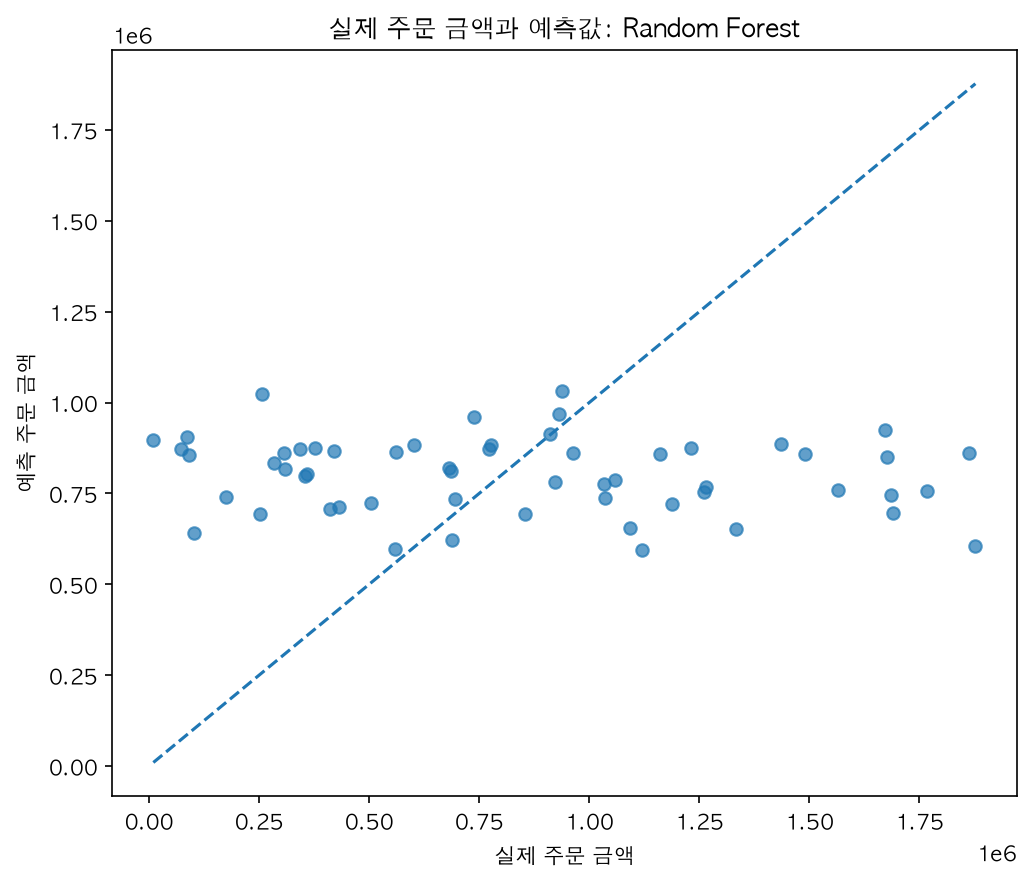

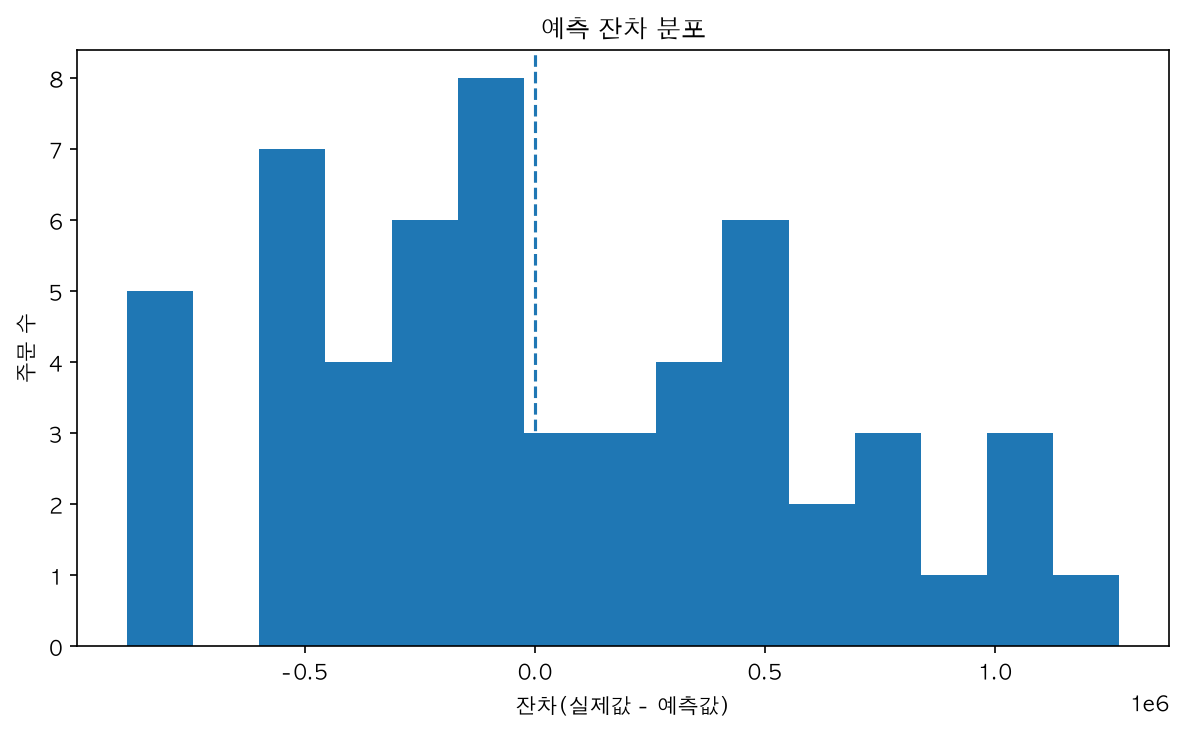

In [15]:
checklist = build_leakage_checklist()
output_paths = save_regression_outputs(
    model_data=model_data,
    split_summary=split_summary,
    feature_audit=feature_audit,
    cv_summary=cv_summary,
    selected_model_name=selected_model_name,
    model_comparison=model_comparison,
    prediction_result=prediction_result,
    validation=validation,
    checklist=checklist,
    report_dir=REPORT_DIR,
)
for name, path in output_paths.items():
    print(name, '->', path.relative_to(PROJECT_ROOT))
for key in ['actual_vs_predicted_figure','residual_figure']:
    display(Image(filename=str(output_paths[key])))

## 독립 계산 및 저장 결과 확인

- Raw를 csv와 Decimal로 별도 읽어 전체 주문별 금액을 대조함
- Final Test 지표를 예측값으로 직접 다시 계산하며 모델 선택에는 사용하지 않음


In [16]:
import csv
from decimal import Decimal
amounts={}
with (PROJECT_ROOT/'data/raw/order_items.csv').open(encoding='utf-8-sig',newline='') as f:
    for r in csv.DictReader(f):
        k=int(r['order_id']); amounts[k]=amounts.get(k,Decimal(0))+Decimal(r['quantity'])*Decimal(r['unit_price'])
assert len(amounts)==len(model_data)
for row in model_data.itertuples():
    assert Decimal(str(row.order_total))==amounts[int(row.order_id)]
np.testing.assert_allclose(clean['order_items']['line_total'],clean['order_items']['quantity']*clean['order_items']['unit_price'],rtol=0,atol=1e-6)
for name, pred in predictions.items():
    y=y_test.to_numpy(); error=y-pred
    row=model_comparison.set_index('model').loc[name]
    assert abs(row.test_MAE-np.abs(error).mean())<1e-6
    assert abs(row.test_RMSE-np.sqrt(np.mean(error**2)))<1e-6
    assert abs(row.test_R2-(1-(error**2).sum()/((y-y.mean())**2).sum()))<1e-10
assert set(model_comparison['model'])=={'Baseline Mean',selected_model_name}
print('Raw Decimal 주문별 Target·line_total·직접 지표 검산: PASS')


Raw Decimal 주문별 Target·line_total·직접 지표 검산: PASS


## 13. 전체 스크립트를 새 프로세스에서 재실행

- 아래 두 실행 명령을 순서대로 별도 프로세스에서 실행함 회귀 모듈에는 Notebook과 같은 날짜 그룹 CV 수정을 적용함
- stdout에는 내부 식별자와 임시 경로가 포함되므로 공개 출력은 종료 코드와 전체 CSV 일치 결과로 제한함


In [17]:
before_csv={p.name:pd.read_csv(p) for p in REPORT_DIR.glob('*.csv') if p.name!='ch09_cv_folds.csv'}
for script in ['prepare_ch09_data.py','run_regression_analysis.py']:
    completed=subprocess.run([sys.executable,'scripts/'+script],cwd=PROJECT_ROOT,capture_output=True,text=True)
    assert completed.returncode==0, completed.stderr
    print('python scripts/'+script,'exit code:',completed.returncode)
for name, expected in before_csv.items():
    pd.testing.assert_frame_equal(expected,pd.read_csv(REPORT_DIR/name),check_exact=False,rtol=0,atol=1e-6)
for name,digest in raw_hashes.items():
    assert hashlib.sha256((PROJECT_ROOT/'data/raw'/f'{name}.csv').read_bytes()).hexdigest()==digest
assert json.loads((PROJECT_ROOT/'frozen_selection.json').read_text())['selected_model']==selected_model_name
for p in REPORT_DIR.rglob('*'):
    if p.is_file():
        out=ARTIFACT_DIR/p.relative_to(REPORT_DIR); out.parent.mkdir(parents=True,exist_ok=True); shutil.copy2(p,out)
shutil.copy2(PROJECT_ROOT/'frozen_selection.json', ARTIFACT_DIR/'frozen_selection.json')
print('저장 CSV 전체 값 일치·Raw SHA-256 불변: PASS')
display(pd.read_csv(REPORT_DIR/'ch09_regression_validation.csv'))
summary={'selected':selected_model_name,'cv':cv_summary.to_dict('records'),'split':split_summary.astype(str).to_dict('records'),'metrics':model_comparison.to_dict('records'),'errors':public_prediction_result(prediction_result).head(3).astype(str).to_dict('records'),'validation':validation.to_dict('records'),'folds':fold_results.astype(str).to_dict('records')}
(ARTIFACT_DIR/'verified_summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2,default=str))


python scripts/prepare_ch09_data.py exit code: 0


python scripts/run_regression_analysis.py exit code: 0
저장 CSV 전체 값 일치·Raw SHA-256 불변: PASS


,check,value,status
0,forbidden_feature_overlap,0,PASS
1,strict_train_before_test,True,PASS
2,selected_model_exists_in_train_cv,True,PASS
3,final_test_contains_baseline,True,PASS
4,final_test_contains_frozen_selected_model,True,PASS
5,test_rows_for_r2,56,PASS


7300

## 제출용 결과 표와 진단 그래프

- 아래 이미지는 실제 실행 DataFrame을 내보낸 표이며 화면 캡처가 아님
- 공식 진단 그래프도 images에 복사하며 내부 식별자는 공개 출력에서 제외함


In [18]:
import matplotlib.pyplot as plt
SUBMISSION_DIR = BASE / 'llm-data-analysis-study' / 'chapter09'
IMAGE_DIR = SUBMISSION_DIR / 'images'
IMAGE_DIR.mkdir(parents=True,exist_ok=True)
def export_table(df, name, title):
    shown=df.copy()
    for col in shown.select_dtypes(include='number'):
        shown[col]=shown[col].map(lambda v: f'{v:,.4f}' if col == 'test_R2' else f'{v:,.2f}')
    if 'reason' in shown:
        import textwrap
        shown['reason']=shown['reason'].map(lambda v: '\n'.join(textwrap.wrap(str(v),width=25)))
    fig,ax=plt.subplots(figsize=(max(10,len(shown.columns)*2.2),max(2.5,len(shown)*0.38+1.4)))
    ax.axis('off'); ax.set_title(title,pad=15)
    table=ax.table(cellText=shown.astype(str).values,colLabels=shown.columns,loc='center',cellLoc='left',bbox=[0,0,1,0.9],colWidths=[0.22,0.10,0.20,0.48] if 'reason' in shown else None)
    table.auto_set_font_size(False); table.set_fontsize(8); table.scale(1,1)
    fig.tight_layout(); fig.savefig(IMAGE_DIR/name,dpi=150,bbox_inches='tight'); plt.close(fig)
export_table(feature_audit,'step02_leakage.png','Feature leakage audit: actual execution result')
export_table(split_summary,'step04_split.png','Chronological split: actual execution result')
export_table(model_comparison,'step06_final_metrics.png','Final Test: baseline vs frozen selected model')
for name in ['ch09_actual_vs_predicted.png','ch09_residual_histogram.png']:
    shutil.copy2(REPORT_DIR/'figures'/name, IMAGE_DIR/name)
# 재실행 processed도 메모리 결과와 전체 값 비교
for name,frame in clean.items():
    disk=pd.read_csv(PROCESSED_DIR/f'{name}_clean.csv')
    expected=pd.read_csv(io.StringIO(frame.to_csv(index=False)))
    pd.testing.assert_frame_equal(expected,disk,check_exact=False,rtol=0,atol=1e-6)
print('재실행 processed 4개 전체 값 일치: PASS')


재실행 processed 4개 전체 값 일치: PASS


# Chapter 09 답안 양식. 회귀 분석으로 숫자 예측하기

> 이 내용을 `chapter09.ipynb`의 Markdown 셀로 작성합니다.

## 제출 정보
이름: 장태원  
GitHub ID: pmsky1  
작성일: 2026-11-09  
최종 Notebook URL: https://github.com/pmsky1/llm-data-analysis-study/blob/main/chapter09/chapter09.ipynb  

## 1. 예측 문제 정의
- Target: order_total = 주문별 quantity × unit_price 합계
- 예측 단위: 주문 1건, 전체 상태 300건
- 예측 시점: 결제수단을 선택한 주문서 작성 중, 상세를 모델에 전달하기 전
- 예측 시점에 알 수 있는 정보: 접수 월·요일, 선택 결제수단, 당시 고객 나이·성별·도시라고 가정함
- 예측 시점에 알 수 없는 정보: 상세 수량·단가·금액과 집계값, 최종 주문 상태

### 나의 해석과 판단
왜 이 예측 시점을 선택했는지 작성하세요.

- 상세가 알려진 뒤에는 직접 합산할 수 있어 상세 없이 추정하는 시점으로 정함
- 결제수단 및 고객 속성의 실제 기록 시각은 확인할 수 없어 운영 전 이 가정을 검증해야 함

## 2. Feature Leakage Audit

| feature | 예측 시점 사용 가능 | Target 계산 재료 | 사후 정보/ID | 최종 사용 | 판단 이유 |
| --- | --- | --- | --- | --- | --- |
| order_month | 예(가정) | 아니오 | 아니오 | 사용 | 접수 일시에서 계산함 |
| order_dayofweek | 예(가정) | 아니오 | 아니오 | 사용 | 접수 일시에서 계산함 |
| age | 예(가정) | 아니오 | 아니오 | 사용 | 예측 당시 나이라고 가정하며 현재 마스터와의 시점 차이는 확인 필요함 |
| payment_method | 예(가정) | 아니오 | 아니오 | 사용 | 주문서에서 선택한 값이 예측 전에 기록된다고 가정함 |
| gender | 예(가정) | 아니오 | 아니오 | 사용 | 예측 당시 고객 마스터의 값이라고 가정함 |
| city | 예(가정) | 아니오 | 아니오 | 사용 | 예측 당시 고객 도시라고 가정하며 변경 이력은 확인 필요함 |
| order_total | 아니오 | 예 | 아니오 | 제외 | Target 자체 |
| line_total | 아니오 | 예 | 아니오 | 제외 | Target을 직접 구성함 |
| quantity | 아니오 | 예 | 아니오 | 제외 | Target 계산 재료 |
| unit_price | 아니오 | 예 | 아니오 | 제외 | Target 계산 재료 |
| item_count | 아니오 | 아니오 | 사후 집계 | 제외 | 상세 확정 후 집계값 |
| total_quantity | 아니오 | 간접 | 사후 집계 | 제외 | 상세 기반 Target 대리값 |
| avg_unit_price | 아니오 | 간접 | 사후 집계 | 제외 | 상세 기반 Target 대리값 |
| order_status | 아니오 | 아니오 | 사후 정보 | 제외 | 최종 결과가 반영될 수 있는 사후 정보 |
| order_id | 발급 시점에 따라 가능 | 아니오 | ID | 제외 | 가용성과 별개로 공식 기준상 제외하며 식별자 패턴을 외울 위험이 있음 |
| customer_id | 예(고객 연결용) | 아니오 | ID | 제외 | 고객 연결에는 사용하지만 공식 기준상 모델 입력에서 제외함 |
| product_id | 아니오 | 아니오 | ID | 제외 | 상세를 알아야 확인하는 상품 식별자 |

- 금지 feature overlap 개수: 0
- 가장 위험하다고 판단한 feature: line_total
- 이유: Target의 직접 구성값이어서 미래 금액을 미리 제공하는 것과 같음

![Leakage 점검](images/step02_leakage.png)

## 3. Target 생성과 관계 검증

### 계산 기준

```text
line_total = quantity × unit_price
order_total = order_id별 line_total 합계
```

- line_total 검증 결과: 764행 계산식 일치, Raw csv+Decimal로 주문별 Target 300건도 전체 대조 PASS
- orders ↔ target 관계 검증 결과: outer merge one_to_one, 주문·Target 300건 모두 매칭, 상세 없는 주문 및 고아 상세 0건
- orders → customers 관계 검증 결과: many_to_one, 300건 모두 연결, 고객·상품·주문 FK 불일치 모두 0건

### 나의 해석과 판단
관계 검증 없이 병합만 수행하면 어떤 문제가 생길 수 있는지 작성하세요.

- inner join은 미연결 주문을 감추고 부모 키 중복은 행과 금액을 늘릴 수 있음
- Raw 150/100/300/764행이 그대로 유지되며 복구·보류·제외가 필요한 숫자 및 관계 오류는 0건임

## 4. Train / Final Test 분할

- Train 시작일: 2025-07-09
- Train 종료일: 2026-04-13
- Train 행 수: 244
- Final Test 시작일: 2026-04-14
- Final Test 종료일: 2026-07-08
- Final Test 행 수: 56
- 같은 달력 날짜 중복 여부: 없음, Train max < Final Test min PASS

### 분할 판단
왜 이번 문제에서 시간 순서 분할을 사용하는지 작성하세요.

- 과거로 학습하여 이후 주문을 예측하는 상황을 평가하기 위해 서로 다른 주문일을 시간순으로 정렬한 뒤 마지막 약 20%의 주문일을 Test로 둠
- 같은 날짜를 묶어 분리하므로 실제 행 비율은 Train 81.33%, Test 18.67%임

![시간 분할](images/step04_split.png)

## 5. Train TimeSeriesSplit 후보 비교

| 모델 | CV MAE 평균 | CV MAE 표준편차 | CV R² 평균 | 비고 |
| --- | ---: | ---: | ---: | --- |
| Baseline Mean | 421,924.14 | 47,631.46 | -0.0253 | 5 date-group folds |
| Linear Regression | 455,325.13 | 57,645.54 | -0.2941 | 5 date-group folds |
| Random Forest | 431,319.99 | 24,810.54 | -0.0951 | 5 date-group folds |

### Train CV로 선택한 비베이스라인 모델
- Selected Model: Random Forest
- 선택 기준: 비베이스라인 두 후보 중 Train CV 평균 MAE가 낮은 모델, n_estimators=300/min_samples_leaf=5/random_state=42 고정
- Final Test 결과를 보기 전에 선택했는가: 최초 실습에서는 예, 이번 날짜 분할 수정은 기존 Test를 이미 본 상태의 재현 평가이며 새 미사용 평가가 아님

### 나의 해석과 판단
CV 평균뿐 아니라 표준편차도 함께 봐야 하는 이유를 작성하세요.

- Random Forest의 fold MAE는 397,300.11~466,589.65원이며 평균 431,319.99원·표준편차 24,810.54원임
- 평균만 보면 시기별 변동을 놓치며 Baseline보다 5개 중 3개 fold에서 MAE가 높음
- 기존 행 기준 TimeSeriesSplit의 같은 날짜 중복을 수정하여 Train의 서로 다른 주문일을 기준으로 5개 fold를 나누고 모든 fold에서 학습 종료일 < 검증 시작일을 확인함
- 이번 수정 기준은 발견한 날짜 중복을 없애는 것이며 Test 성능으로 분할·후보·하이퍼파라미터를 탐색하지 않음 독립적인 최종 성능 확인에는 새 미래 데이터가 필요함
- 결측 대체·표준화·인코딩은 fold별 Pipeline fit으로 수행함 공통 데이터의 age 등에는 결측이 없어 사전 통계 대체가 발생하지 않음

## 6. Final Test: Baseline vs Frozen Model

| 모델 | selection role | Train MAE | Test MAE | Test RMSE | Test R² | Baseline 대비 MAE 개선율 |
| --- | --- | ---: | ---: | ---: | ---: | ---: |
| Baseline Mean | baseline | 416,266.1919 | 443,449.6487 | 522,189.6996 | -0.0011 | 0.0000 |
| Frozen Selected Model | selected_by_train_cv | 326,438.4781 | 458,819.9172 | 548,190.4467 | -0.1033 | -3.4700 |

![최종 회귀 평가](images/step06_final_metrics.png)

### 결과 관찰

- Random Forest의 Test MAE 458,819.92원으로 Baseline 443,449.65원보다 15,370.27원 높고 개선율은 -3.47%임

### 나의 해석과 판단
- Frozen Model이 baseline보다 실제로 개선되었는가?
- 개선 없음 CV에서도 Baseline이 더 낮지만 공식 실습 기준대로 비베이스라인 후보를 선택해 최종 비교함
- MAE와 RMSE 차이에서 무엇을 볼 수 있는가?
- MAE는 주문당 평균 절대오차 약 45.88만원, RMSE는 약 54.82만원으로 큰 오차의 영향도 있음 Train MAE 약 32.64만원보다 Test 오차가 커 일반화 한계가 보임
- R²는 어떻게 해석할 수 있는가?
- R² -0.1033은 이 Test의 실제 평균을 일정하게 예측하는 기준보다 제곱오차가 크다는 뜻임 Train 평균을 사용하는 Dummy와 R²의 기준은 구분해야 함

### 업무·분석적 의미
현재 오차 수준이 실제 사용에서 어떤 의미인지 작성하세요.

- 주문별 금액 결정이나 예산 배분에 적용하기에는 평균 절대오차가 크고 Baseline 대비 추가 가치가 확인되지 않음
- 오차 허용 한도가 없으며 취소·환불을 포함한 주문 금액을 순매출로 해석할 수 없음

## 7. 대표 오차 사례

### 사례 1
- 실제값: 1,877,000.00원
- 예측값: 605,528.72원
- residual: 1,271,471.28원
- absolute error: 1,271,471.28원
- 관찰: 2026-06-15 주문을 약 127.15만원 과소 예측함
- 가능한 이유 후보: 상세 정보가 없는 입력으로 고액 주문을 구별하기 어려웠을 가능성이 있으나 원인은 확정할 수 없음
- 추가 확인: 해당 주문의 상세와 프로모션·고객 속성의 당시 기록을 진단용으로 확인하고 예측 전에 확보 가능한 정보와 구분해야 함
- 현재 모델의 한계: 큰 주문 금액 차이를 설명할 입력이 부족하며 상세 기반 금액을 Feature로 다시 넣을 수 없음

### 사례 2
- 실제값: 1,767,000.00원
- 예측값: 756,889.65원
- residual: 1,010,110.35원
- absolute error: 1,010,110.35원
- 관찰: 2026-06-19 주문을 약 101.01만원 과소 예측함
- 가능한 이유 후보: 상세 정보가 없는 입력으로 고액 주문을 구별하기 어려웠을 가능성이 있으나 원인은 확정할 수 없음
- 추가 확인: 해당 주문의 상세와 프로모션·고객 속성의 당시 기록을 진단용으로 확인하고 예측 전에 확보 가능한 정보와 구분해야 함
- 현재 모델의 한계: 큰 주문 금액 차이를 설명할 입력이 부족하며 상세 기반 금액을 Feature로 다시 넣을 수 없음

> 원인을 데이터가 직접 보여 주지 않는다면 사실처럼 단정하지 않습니다.

## 8. Validation Evidence

`reports/ch09_regression_validation.csv` 기준으로 작성하세요.

| check | value | status |
| --- | --- | --- |
| forbidden_feature_overlap | 0 | PASS |
| strict_train_before_test | True | PASS |
| selected_model_exists_in_train_cv | True | PASS |
| final_test_contains_baseline | True | PASS |
| final_test_contains_frozen_selected_model | True | PASS |
| test_rows_for_r2 | 56 | PASS |

### FAIL 항목
- 없음 / 있음: 없음, 6개 모두 PASS
- 있다면 원인과 수정 내용: 해당 없음 단 자동 PASS는 모델 성능이나 실제 시점 가용성을 보장하지 않음
- 위 6개 자동 PASS는 가입일과 주문일의 업무상 선후 관계를 검사하지 않음 별도 검사에서 가입일 이전 주문 56건을 발견하여 업무 시간 관계는 미해결로 기록함


## 9. Evidence와 공개 범위

### 생성된 Evidence
- [x] `ch09_regression_split_summary.csv`
- [x] `ch09_regression_feature_audit.csv`
- [x] `ch09_regression_cv_summary.csv`
- [x] `ch09_regression_model_comparison.csv`
- [x] `ch09_regression_validation.csv`
- [x] `ch09_regression_checklist.csv`

### Internal 파일
- [x] `ch09_regression_model_data_internal.csv`
- [x] `ch09_regression_predictions_internal.csv`

### 공개 결과
- [x] `ch09_regression_report.md`
- [x] `ch09_actual_vs_predicted.png`
- [x] `ch09_residual_histogram.png`

### 공개 범위 판단
왜 `order_id`가 포함된 예측 결과를 Internal로 구분해야 하는지 작성하세요.

- 식별자는 거래를 다시 연결할 수 있어 내부 진단 파일에만 남기고 공개 표·그래프에서는 제외함
- 생성 CSV·보고서는 작업용 reports/chapter09에 보존하며 제출 폴더에는 Notebook과 images만 둠

## 10. 최종 사용 판단

- [ ] 현재 수준에서 참고용 사용 가능
- [ ] 추가 검증 후 사용 가능
- [x] 현재 데이터로는 사용 보류

### 판단 근거
1. 날짜 그룹 Train CV에서 Random Forest 평균 MAE 431,319.99원·표준편차 24,810.54원이며 Baseline 421,924.14원보다 나쁨
2. 날짜를 분리하고 금지 Feature 0개로 평가했지만 Test MAE 458,819.92원·RMSE 548,190.45원·R² -0.1033, Baseline 개선율 -3.47%임
3. 큰 오차 사례에서 100만원 이상 과소 예측이 보이며 단일 56건 Test와 고객 속성 시점 가정만으로 운영 일반화를 확정할 수 없음

### 업무적 위험

- 고액 주문을 과소 추정하여 예산·수요 판단을 왜곡할 수 있음

### 현재 데이터의 한계

- 교육용 300주문으로 한 기간만 평가했고 고객 이력·시점별 속성 변경·상품군 및 프로모션 원인은 확인할 수 없음
- 동일 고객이 Train/Test에 반복될 수 있어 신규 고객 일반화 검증과도 구분해야 함


- 가입일보다 주문일이 빠른 주문 56건(고객 31명, Train 51건·Test 5건)이 있어 고객 속성이 예측 시점에 존재했다는 가정을 확정할 수 없음
- 가입일의 업무상 정의와 교육용 데이터 생성 규칙을 확인하기 전까지 원본을 임의 삭제·수정하지 않으며 모델 운영 사용을 보류함

### 다음 개선 우선순위
1. 운영 시점에 결제수단·고객 속성을 확보할 수 있는지 기록 시각 확인
2. 가입일 이전 주문의 업무상 의미를 확인하고 신규 고객·기간별 안정성을 별도로 점검
3. 예측 전에 확보되는 추가 정보와 새 미사용 미래 평가 기간을 수집해 Baseline부터 재비교

## 11. 전체 재실행 확인

실행 명령:

```powershell
python scripts/prepare_ch09_data.py
python scripts/run_regression_analysis.py
```

- 실행 성공 여부: 두 명령 별도 프로세스 종료 코드 0
- Train CV Selected Model: Random Forest, Test 확인 후 교체 없음
- Final Validation 전체 PASS 여부: 6개 전체 PASS
- Notebook 결과와 스크립트 결과의 일관성: 보고서 CSV 8개 및 processed 4개 전체 값 일치, Raw 4개 SHA-256 불변, Raw Decimal 금액 및 직접 지표 검산 PASS

## 최종 체크

- [x] Target과 예측 시점을 정의했습니다.
- [x] Leakage Audit을 수행했습니다.
- [x] Target 계산과 관계 검증을 확인했습니다.
- [x] Train과 Final Test가 시간 순서로 엄격히 분리되었습니다.
- [x] 전처리가 Pipeline 내부에서 학습됩니다.
- [x] Train TimeSeriesSplit으로 후보를 비교했습니다.
- [x] Final Test 전에 Selected Model을 고정했습니다.
- [x] Final Test에서는 Baseline과 Frozen Model만 비교했습니다.
- [x] MAE, RMSE, R²를 함께 해석했습니다.
- [x] 대표 오차 사례를 관찰과 가설로 구분했습니다.
- [x] Validation Evidence가 모두 PASS입니다.
- [x] Internal 결과와 공개 결과를 구분했습니다.
- [x] 낮은 성능도 숨기지 않았습니다.
- [x] 전체 스크립트를 재실행했습니다.
- [ ] 최종 Notebook URL을 제출합니다.

- 선택 고정 항목은 최초 평가 절차를 확인한 것임 날짜 그룹 CV 수정 후에는 기존 Test를 재사용했으며 독립 평가의 한계가 남음
- Pipeline 학습 항목은 실제 적용된 통계 처리를 기준으로 확인함 공통 준비 함수의 사전 중앙값 대체는 현재 데이터에서 발생하지 않았으며 일반적인 누수 안전성을 보장하지 않음


## LLM 활용 및 직접 검증

### 사용한 AI 도구

- ChatGPT

### 이번 대화의 요청과 제안 요약

- 요청: 제공된 Chapter09 요구를 기준으로 예측 시점·누수·시간 분할·Baseline·모델 선택 순서를 지키고 Chapter05의 값 손실·관계 오류가 반복되지 않도록 검증함
- ChatGPT 제안: 공식 6개 Feature만 사용하고 PK/FK·행 손실 gate, Raw Decimal Target 검산, fold별 성능, 선택 고정 기록과 별도 프로세스 재실행을 추가함
- 검증: 실제 300주문 Target 전체 일치, FK 0건, 금지 Feature 0개, Train CV로 Random Forest 선택 후 Final Test 2개 모델만 비교, Validation 6개 PASS 확인함
- 채택: 누수 차단과 독립 검산·공식 후보 비교 절차를 채택함
- 수정: 공식 출력의 order_id와 로컬 절대 경로는 공개 표에서 제외함
- 보류: Random Forest의 운영 사용은 Baseline 대비 MAE -3.47% 개선율과 큰 오차를 근거로 보류함
- 남은 한계: Final Test 자동 PASS와 별개로 실제 고객 속성의 시점 가용성과 가입일 이전 주문 56건의 업무상 시간 관계는 미해결임 내부 CV 날짜 중복은 수정했으며 이미 사용한 Test라는 평가 한계는 남음

### 진단 그래프 관찰

![실제값과 예측값](images/ch09_actual_vs_predicted.png)

- 관찰: 큰 실제 금액에 비해 예측값이 작아지는 사례가 보이고 상위 오차 2건은 각각 약 127.15만원·101.01만원 과소 예측임
- 판단: 현재 허용한 입력으로 고액 주문을 구별하는 데 한계가 있음
- 업무 의미: 개별 주문 금액을 확정하는 판단에는 사용을 보류함
- 한계: 그래프만으로 상품 구성이나 구매 동기를 원인으로 단정할 수 없음

![잔차 분포](images/ch09_residual_histogram.png)

- 관찰: 실제값-예측값 잔차가 0 양쪽에 분포하고 큰 양수 잔차는 과소 예측을 뜻함
- 판단: RMSE가 MAE보다 커 큰 오차도 함께 확인해야 함
- 업무 의미: 평균 오차만으로 고액 주문의 위험을 가릴 수 없음
- 한계: 56건 한 구간의 분포로 다른 계절·신규 고객의 성능을 보장할 수 없음

### 추가 검토와 반영

- 요청: 과거 감점 기준으로 발견한 검토 사항을 수정함
- 수정: 날짜 변환 성공과 업무상 선후 관계를 구분하는 검사를 추가하고, 내부 CV를 주문일 그룹 기준으로 바꿈
- 검증: 5개 fold의 날짜 중복 0건, 가입일 이전 주문 56건 확인, Notebook과 별도 프로세스 결과 일치함
- 판단: 가입일 의미는 확인되지 않아 임의 삭제를 보류하고, 이미 확인한 Test의 재현 결과를 새 독립 평가로 해석하지 않음

### 제출 전 별도 ChatGPT 검토 Evidence

![검토 요청과 답변 시작](images/step07_llm_prompt.png)

- 사용자가 제공한 실제 대화 화면이며 과제 요구사항과 답변 시작 부분을 확인할 수 있음 질문의 나머지 부분은 화면에서 접혀 있음

![검토 근거와 지적 사항](images/step08_llm_review.png)

- 외부 검토는 Notebook 코드·저장 Output·답안을 대조한 것이며 Notebook 전체를 재실행한 검증은 아님
- 채택: Test 재사용 설명이 일부 안내·체크리스트와 혼동될 수 있다는 지적을 반영하여 해당 위치에 최초 평가와 수정 후 재현 평가를 구분함
- 부분 채택: 참조 저장소 필요 조건은 기존에 명시돼 있으나 폴더 배치 그림을 추가하여 실행 의존성을 명확하게 함
- 확인: Pipeline 밖 나이 중앙값 대체 코드가 있으나 현재 Raw에 나이 결측·변환 실패가 없어 대체 0건임 현재 결과에 누수가 발생했다고 단정하지 않으며 다른 데이터에 재사용할 때 수정할 사항으로 명시함
- 유지: 가입일 이전 주문 56건과 고객 속성의 과거 시점 가용성은 해결되지 않았으므로 업무 사용 보류를 유지함
- 검토 범위: 별도 ChatGPT에는 로컬 CSV와 images 폴더가 없어 원자료·연결 이미지 전체를 직접 확인하지 못함 원본·계산·이미지 검증은 이 Notebook의 실행 결과와 로컬 점검으로 구분함
